##### The goal of this exercise is to get into some first contact with Python, Pandas data frames, and the many opportunities how to quickly generate static charts from data frames.

For the first exercise, load the provided CSV file, do some data cleaning, and check if your cleaning operation was successful using visualization. For inspiration, browse through some Kaggle notebooks. The original data was downloaded from Kaggle. 

The main purpose of the notebook is to preprocess the CSV file for further visualization. The following steps have to be performed: 


- Read the CSV using Pandas. The data has been slightly preprocessed in Excel to clean and simplify it. See the pandas.read_csv documentation to check how to parse the CSV correctly! (0.5 points)
- Remove unusable rows. The provided CSV may contain rows containing aggregated values or headers we do not need for our final visualization (we are only interested in the individual indicators, not their grouping into pre-defined categories). These rows need to be removed. (0.75 points)
- Take care of missing values. Sci-kit learn provides different data imputation methods. (0.75 points)
    (Hint: You may need to impute before you completely filter your data-frame. You need to make an educated judgment). 
- Visualize the data (twice). Every submitted notebook should contain at least two visualizations using at least two different Python visualization libraries. A list of the most wide-spread Python visualization libraries can be found in this article. You must concisely describe and explain each visualization and your decisions in a Markdown field. You will not receive the points for this task if you did not add a description/explanation. (max. 1.25 points per visualization) Only the first two visualizations will be graded. Submitting more than two visualizations will not result in additional points.
- Save the resulting table as CSV. To be sure that the data is correctly saved, you can load it again. You will have to work with this clean dataset for the second exercise. (0.5 points)


# Group-27 members:
+ **Cam Le - 12551211**
+ **Zixuan Sun Sun - 12551596**
+ **Ron Thankachan Alumkal - 12550228**


# 0. Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.experimental import enable_iterative_imputer  # This is required to use IterativeImputer
from sklearn.impute import SimpleImputer, IterativeImputer, KNNImputer

# 1. Read the CSV using Pandas.
The data has been slightly preprocessed in Excel to clean and simplify it. See the pandas.read_csv documentation to check how to parse the CSV correctly! (0.5 points)

In [2]:
# Load the dataset
df = pd.read_csv("agriRuralDevelopment.csv")
print(f"dataFrame shape: {df.shape}")
df.head()

dataFrame shape: (13908, 55)


,Country Name,Country Code,year,Access to electricity (% of population),"Access to electricity, rural (% of rural population)",Agricultural irrigated land (% of total agricultural land),Agricultural land (% of land area),Agricultural land (sq. km),"Agricultural machinery, tractors","Agricultural machinery, tractors per 100 sq. km of arable land",...,Permanent cropland (% of land area),"Population, total",Rural land area (sq. km),Rural land area where elevation is below 5 meters (% of total land area),Rural land area where elevation is below 5 meters (sq. km),Rural population,Rural population (% of total population),Rural population growth (annual %),Rural population living in areas where elevation is below 5 meters (% of total population),Surface area (sq. km)
0,Afghanistan,AFG,1960,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8996973.0,NaN,NaN,NaN,8241137.0,91.599,NaN,NaN,NaN
1,Afghanistan,AFG,1961,NaN,NaN,NaN,57.745918,377000.0,120.0,0.156863,...,0.076586,9169410.0,NaN,NaN,NaN,8373138.0,91.316,1.589040,NaN,652860.0
2,Afghanistan,AFG,1962,NaN,NaN,NaN,57.837821,377600.0,150.0,0.194805,...,0.091903,9351441.0,NaN,NaN,NaN,8512056.0,91.024,1.645479,NaN,652860.0
3,Afghanistan,AFG,1963,NaN,NaN,NaN,57.914407,378100.0,200.0,0.258065,...,0.091903,9543205.0,NaN,NaN,NaN,8657977.0,90.724,1.699758,NaN,652860.0
4,Afghanistan,AFG,1964,NaN,NaN,NaN,58.010906,378730.0,200.0,0.256410,...,0.111816,9744781.0,NaN,NaN,NaN,8810646.0,90.414,1.747967,NaN,652860.0


In [3]:
# Print column names, distinct values and data types
summary = pd.DataFrame({
    "dtype": df.dtypes,
    "unique": df.nunique(),
}).sort_values("unique")
summary

,dtype,unique
year,int64,61
CPIA gender equality rating (1=low to 6=high),float64,76
Average precipitation in depth (mm per year),float64,170
Rural land area where elevation is below 5 meters (sq. km),float64,181
Rural land area (sq. km),float64,190
Rural land area where elevation is below 5 meters (% of total land area),float64,201
Country Code,object,228
Country Name,object,228
"Annual freshwater withdrawals, agriculture (% of total freshwater withdrawal)",float64,531
Rural population living in areas where elevation is below 5 meters (% of total population),float64,538


In [4]:
# Get columns which dtype is object, str, etc
object_cols = df.select_dtypes(include="object").columns
print(f"object columns: {list(object_cols)}\n")

object columns: ['Country Name', 'Country Code']



# 2. Remove unusable rows.
The provided CSV may contain rows containing aggregated values or headers we do not need for our final visualization (we are only interested in the individual indicators, not their grouping into pre-defined categories).
These rows need to be removed. (0.75 points)

In [5]:
# Identify rows where "Country Name" contains certain keywords (we have manually checked the unique values in the column)
mask = df["Country Name"].str.contains(
    "Asia|Europe|America|Africa|Arab|OECD|world|state|income|low|middle|upper|high",
    case=False,  # not case-sensitive
    na=False,  # treat NaN as False
)

print(f"Percentage of rows matching the mask: {round(mask.sum() / len(df) * 100, 2)}%")

# Get the indices of rows that match the mask
unusable_rows = df[mask].index

print(f"Unique 'Country Name' values in unusable rows: {df.loc[unusable_rows, 'Country Name'].unique()}")

Percentage of rows matching the mask: 9.21%
Unique 'Country Name' values in unusable rows: ['American Samoa' 'Arab World' 'Caribbean small states'
 'Central African Republic' 'Central Europe and the Baltics'
 'East Asia & Pacific' 'Egypt, Arab Rep.' 'Europe & Central Asia'
 'European Union' 'Latin America & Caribbean' 'Middle East & North Africa'
 'North America' 'Saudi Arabia' 'Small states' 'South Africa' 'South Asia'
 'Sub-Saharan Africa' 'Syrian Arab Republic' 'United Arab Emirates'
 'United States' 'World']


In [6]:
# Refine the mask to only include aggregated values
aggregated_values = [
    "Arab World",
    "Caribbean small states",
    "Central Europe and the Baltics",
    "East Asia & Pacific",
    "Europe & Central Asia",
    "European Union",
    "Latin America & Caribbean",
    "Middle East & North Africa",
    "North America",
    "Small states",
    "South Asia",
    "Sub-Saharan Africa",
    "World",
]

# Remove rows that column "Country Name" contains any of the aggregated values
df_clean = df[~df["Country Name"].isin(aggregated_values)].copy()

print(f"Removed rows: {df.shape[0] - df_clean.shape[0]}")
print(f"df shape: {df.shape}")
print(f"df_clean shape: {df_clean.shape}")

Removed rows: 793
df shape: (13908, 55)
df_clean shape: (13115, 55)


In [7]:
# Sort by country and year
df_clean.sort_values(
    by=["Country Name", "year"],
    inplace=True,
)
df_clean.reset_index(drop=True, inplace=True)

# 3. Take care of missing values.
    Sci-kit learn provides different data imputation methods. (0.75 points)
    (Hint: You may need to impute before you completely filter your data-frame. You need to make an educated judgment).

In [8]:
# Check the data after removing the aggregated entities
print(f"dataFrame shape: {df_clean.shape}")
df_clean.head()

dataFrame shape: (13115, 55)


,Country Name,Country Code,year,Access to electricity (% of population),"Access to electricity, rural (% of rural population)",Agricultural irrigated land (% of total agricultural land),Agricultural land (% of land area),Agricultural land (sq. km),"Agricultural machinery, tractors","Agricultural machinery, tractors per 100 sq. km of arable land",...,Permanent cropland (% of land area),"Population, total",Rural land area (sq. km),Rural land area where elevation is below 5 meters (% of total land area),Rural land area where elevation is below 5 meters (sq. km),Rural population,Rural population (% of total population),Rural population growth (annual %),Rural population living in areas where elevation is below 5 meters (% of total population),Surface area (sq. km)
0,Afghanistan,AFG,1960,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8996973.0,NaN,NaN,NaN,8241137.0,91.599,NaN,NaN,NaN
1,Afghanistan,AFG,1961,NaN,NaN,NaN,57.745918,377000.0,120.0,0.156863,...,0.076586,9169410.0,NaN,NaN,NaN,8373138.0,91.316,1.589040,NaN,652860.0
2,Afghanistan,AFG,1962,NaN,NaN,NaN,57.837821,377600.0,150.0,0.194805,...,0.091903,9351441.0,NaN,NaN,NaN,8512056.0,91.024,1.645479,NaN,652860.0
3,Afghanistan,AFG,1963,NaN,NaN,NaN,57.914407,378100.0,200.0,0.258065,...,0.091903,9543205.0,NaN,NaN,NaN,8657977.0,90.724,1.699758,NaN,652860.0
4,Afghanistan,AFG,1964,NaN,NaN,NaN,58.010906,378730.0,200.0,0.256410,...,0.111816,9744781.0,NaN,NaN,NaN,8810646.0,90.414,1.747967,NaN,652860.0


In [9]:
# Copy data for imputation
df_impute = df_clean.copy()
print(f"dataFrame shape: {df_impute.shape}")
print(f"Number of columns: {len(df_impute.columns)}")

dataFrame shape: (13115, 55)
Number of columns: 55


## 3.1 Random checks to find suitable methods to deal with missing values 

In [10]:
df_impute.describe().T

,count,mean,std,min,25%,50%,75%,max
year,13115.0,1.990000e+03,1.760749e+01,1.960000e+03,1.975000e+03,1.990000e+03,2.005000e+03,2.020000e+03
Access to electricity (% of population),5083.0,8.017830e+01,3.007949e+01,1.000000e-02,6.776337e+01,9.913060e+01,1.000000e+02,1.000000e+02
"Access to electricity, rural (% of rural population)",4889.0,7.569446e+01,3.485992e+01,1.000000e-02,5.339372e+01,9.947906e+01,1.000000e+02,1.000000e+02
Agricultural irrigated land (% of total agricultural land),834.0,9.889010e+00,1.241124e+01,0.000000e+00,1.198764e+00,5.166759e+00,1.317988e+01,5.971149e+01
Agricultural land (% of land area),10532.0,3.703379e+01,2.243276e+01,2.628205e-01,1.761787e+01,3.767414e+01,5.517241e+01,9.344075e+01
Agricultural land (sq. km),10544.0,2.277477e+05,6.377681e+05,3.000000e+00,1.430000e+03,2.844650e+04,1.733850e+05,5.278330e+06
"Agricultural machinery, tractors",6028.0,1.365694e+05,4.912831e+05,1.000000e+00,2.452500e+02,4.797000e+03,5.592500e+04,5.470000e+06
"Agricultural machinery, tractors per 100 sq. km of arable land",5929.0,2.918211e+02,5.872503e+02,4.348204e-03,1.333333e+01,8.199872e+01,2.545770e+02,6.600462e+03
Agricultural methane emissions (% of total),7882.0,4.777368e+01,2.661166e+01,0.000000e+00,2.787335e+01,5.021765e+01,6.980915e+01,9.923094e+01
Agricultural methane emissions (thousand metric tons of CO2 equivalent),8600.0,1.387447e+04,4.817641e+04,0.000000e+00,3.802124e+01,1.949386e+03,8.589669e+03,5.812218e+05


In [11]:
# df_impute.groupby("Country Name").count()

In [12]:
# Check missing values percentage in the cleaned dataframe
round(df_impute.isna().sum() / len(df_impute) * 100, 2).sort_values(ascending=False)

Rural land area where elevation is below 5 meters (sq. km)                                    95.95
Rural land area where elevation is below 5 meters (% of total land area)                      95.95
Rural land area (sq. km)                                                                      95.95
Rural population living in areas where elevation is below 5 meters (% of total population)    95.95
Annual freshwater withdrawals, agriculture (% of total freshwater withdrawal)                 95.75
Agricultural irrigated land (% of total agricultural land)                                    93.64
Literacy rate, adult total (% of people ages 15 and above)                                    92.97
Fertilizer consumption (% of fertilizer production)                                           91.30
CPIA gender equality rating (1=low to 6=high)                                                 91.28
Average precipitation in depth (mm per year)                                                  84.41


In [13]:
# print columns containing rows with missing values between lower and upper thresholds
cols_by_missing_values_percentage = {}
for missing_value_threshold_lower in [i*10 for i in range(0, 10)]:
    missing_value_threshold_upper = missing_value_threshold_lower + 10

    # Get columns with missing values percentage between the lower and upper thresholds
    cols_between_thresholds = (round(df_impute.isna().sum() / len(df_impute) * 100, 2) > missing_value_threshold_lower) & (round(df_impute.isna().sum() / len(df_impute) * 100, 2) <= missing_value_threshold_upper)

    # Store the column names in the dictionary
    cols_by_missing_values_percentage[f"{missing_value_threshold_lower}-{missing_value_threshold_upper}%"] = {
        col: float(round(df_impute[col].isna().sum() / len(df_impute) * 100, 2))
        for col in cols_between_thresholds[cols_between_thresholds].index.tolist()
    }

cols_by_missing_values_percentage

{'0-10%': {'Land area (sq. km)': 7.35,
  'Population, total': 2.24,
  'Rural population': 3.16,
  'Rural population (% of total population)': 2.84,
  'Rural population growth (annual %)': 8.16,
  'Surface area (sq. km)': 7.35},
 '10-20%': {'Agricultural land (% of land area)': 19.7,
  'Agricultural land (sq. km)': 19.6,
  'Birth rate, crude (per 1,000 people)': 10.69,
  'Death rate, crude (per 1,000 people)': 10.87},
 '20-30%': {'Arable land (% of land area)': 20.74,
  'Arable land (hectares per person)': 20.8,
  'Arable land (hectares)': 20.69,
  'Crop production index (2004-2006 = 100)': 22.75,
  'Food production index (2004-2006 = 100)': 21.88,
  'GDP per capita (current US$)': 25.48,
  'Livestock production index (2004-2006 = 100)': 22.15,
  'Mortality rate, infant (per 1,000 live births)': 21.08,
  'Permanent cropland (% of land area)': 25.43},
 '30-40%': {'Agricultural methane emissions (% of total)': 39.9,
  'Agricultural methane emissions (thousand metric tons of CO2 equivalent

## 3.2 Remove columns where the percentage of missing values is too large

It's hard to say which percentage of missing values is "large"
but we think that a descriptive column (like Rural land area, ...) with > 50% of null values
can not show us informative and generalized information even with missing values imputation
as it's likely to be added more noise instead of value. 

In case of building machine learning model we can try different imputation strategies but 
in the topic of information visualization, we dicided to use a threshold of null percentage
to drop columns 

Reference to choose a threshold for percentage of null. 
- https://medium.com/@JacintahKimeu/how-many-null-values-is-too-many-7dc55653664
- https://datascience.stackexchange.com/questions/67512/what-do-i-do-when-my-column-has-50-data-missing
- https://datascience.stackexchange.com/questions/57405/when-to-use-missing-data-imputation-in-the-data-analysis-problem?rq=1
- https://pmc.ncbi.nlm.nih.gov/articles/PMC6547017/#:~:text=Statistical%20guidance%20articles%20have%20stated,18%5D%2C%20%5B19%5D.
- https://www.reddit.com/r/statistics/comments/xlx4xx/q_what_percentage_of_na_is_still_acceptable_how/
- https://www.kaggle.com/discussions/questions-and-answers/499580
- https://www.sciencedirect.com/science/article/pii/S0895435618308710#:~:text=Researchers%20in%20a%20variety%20of,23%5D%2C%20%5B24%5D.

In [14]:
# Remove columns with more than 50% null values
NULL_THRESHOLD = 50
cols_to_drop = list(
    round(df_impute.isna().sum() / len(df_impute) * 100, 2)[
        lambda x: x > NULL_THRESHOLD
    ].index
)

print(f"df_impute shape before dropping columns: {df_impute.shape}")
df_impute.drop(
    columns=cols_to_drop,
    inplace=True,
)

print(f"Dropped {len(cols_to_drop)} columns: {cols_to_drop}")
print(f"df_impute shape after dropping columns: {df_impute.shape}")

df_impute shape before dropping columns: (13115, 55)
Dropped 21 columns: ['Access to electricity (% of population)', 'Access to electricity, rural (% of rural population)', 'Agricultural irrigated land (% of total agricultural land)', 'Agricultural machinery, tractors', 'Agricultural machinery, tractors per 100 sq. km of arable land', 'Annual freshwater withdrawals, agriculture (% of total freshwater withdrawal)', 'Average precipitation in depth (mm per year)', 'CPIA gender equality rating (1=low to 6=high)', 'Employment in agriculture (% of total employment) (modeled ILO estimate)', 'Employment in agriculture, female (% of female employment) (modeled ILO estimate)', 'Employment in agriculture, male (% of male employment) (modeled ILO estimate)', 'Fertilizer consumption (% of fertilizer production)', 'Fertilizer consumption (kilograms per hectare of arable land)', 'Forest area (% of land area)', 'Forest area (sq. km)', 'Literacy rate, adult total (% of people ages 15 and above)', 'Net 

## 3.3 Impute missing values

### 3.3.1 Manual handling columns

A bit time consuming as we need to understand data but this gives us control of the values will be filled in.

We can not impute missing values for columns "Population, total" and "Rural population" with stats from the colums
like mean, median, max, 0 ... as there exist trends for each country (for example: population grows over years)

What we will do:
+ Fill the first and last value if they are null using their previous or next not-null value.

+ `Rural population` column, for each country:
    - Use `Rural population growth (annual %)` at year `y` and `Rural population` at year `y-1` to calculate `Rural population` at year `y` if it is null. 
    - Or use `Rural population` at year `y-1` and year `y+1` to calculate `Rural population` at year `y` if it is null.
    - Other cases: Fill in using linear interpolation method
    - If entire data for a country is null -> `Rural population` will be 0.

+ `Rural population growth (annual %)` column, for each country:
    - After filling missing values  of the `Rural population` column
-> there does not exist any null
-> we can easily filled in missing value for `Rural population growth (annual %)` column by calculating the growth from year `y` and year `y+1`

+ `Rural population (% of total population)` column, for each country:
    - We can impute missing value by dividing `Rural population` by `Population, total`
    - Other cases: Fill in using linear interpolation method

+ `Population, total` column, for each country:
    - Now the `Rural population` and `Rural population (% of total population)` column do not have null values anymore
then can do the imputation using calculation from those values.

In [15]:
# Get all contry_name that entire column "Rural population" is null (we will assume that the rural population is 0 in these countries)
countries_all_null = (
    df_impute.groupby("Country Name")["Rural population"]
    .apply(lambda x: x.isna().all())
)

countries_all_null[countries_all_null].index.tolist()

['Kosovo', 'St. Martin (French part)']

In [16]:
# Get all country where rural population = 0 for all years
for col in ["Rural population", "Population, total"]:
    countries_all_zero = (
        df_impute.groupby("Country Name")[col]
        .apply(lambda x: (x == 0).all())
    )
    print(f"Countries where '{col}' is 0 for all years: {countries_all_zero[countries_all_zero].index.tolist()}")

Countries where 'Rural population' is 0 for all years: []
Countries where 'Population, total' is 0 for all years: []


In [17]:
def fillna_first_and_last_value_by_country(
    country_df: pd.DataFrame,
    target_col: str,
) -> pd.DataFrame:

    if pd.isna(country_df.iloc[0][target_col]):
        # Go forward until we find a non-null value and fill the first value with it
        for position in range(1, len(country_df)):
            if pd.notna(country_df.iloc[position][target_col]):
                country_df.loc[country_df.index[0], target_col] = country_df.iloc[position][target_col]
                break

    if pd.isna(country_df.iloc[-1][target_col]):
        # Go backward until we find a non-null value and fill the last value with it
        for position in range(len(country_df)-2, -1, -1):
            if pd.notna(country_df.iloc[position][target_col]):
                country_df.loc[country_df.index[-1], target_col] = country_df.iloc[position][target_col]
                break

    return country_df


def get_df_by_country(
    df: pd.DataFrame,
    country: str,
    cols: list[str],
    sort_by_col: str = None,
) -> pd.DataFrame:
    # Get dataframe for a specific country and specific columns, and sort by a specific column if provided
    country_df = df.loc[
        df["Country Name"] == country,
        cols,
    ]

    if sort_by_col:
        country_df = country_df.sort_values(by=sort_by_col)

    return country_df


def fillna_interpolate_by_country(
    country_df: pd.DataFrame,
    target_col: str,
) -> pd.DataFrame:
    # Interpolate remaining missing values in the target column using linear interpolation, and then forward fill and backward fill any remaining missing values
    country_df[target_col] = (
        country_df[target_col]
        .interpolate(method="linear", limit_direction="both")
        .ffill()
        .bfill()
    )

    # Make sure there is no missing value as the interpolation may not work if entire column is null or only exist 1 value in the column.
    # Assume 0 for these cases as filling with mean does not make sense
    country_df = country_df.fillna(0)    

    return country_df


def fillna_rural_population_by_country(
    df: pd.DataFrame,
    target_col: str = "Rural population",
    ref_col: str = "Rural population growth (annual %)",
) -> pd.DataFrame:
    for country in df["Country Name"].unique():
        country_df = get_df_by_country(
            df,
            country=country,
            cols=["year", ref_col, target_col],
            sort_by_col="year",
        )

        # First value of each country is null, we can fill it with the second value if the second value is not null
        country_df = fillna_first_and_last_value_by_country(country_df, target_col)

        # Other values
        for position in range(1, len(country_df)-1):
            row_index = country_df.index[position]

            if pd.notna(country_df.iloc[position][target_col]):
                continue

            prev_value = country_df.iloc[position - 1][target_col]
            next_value = country_df.iloc[position + 1][target_col]
            growth = country_df.iloc[position][ref_col]

            if pd.notna(prev_value) and pd.notna(growth):
                country_df.loc[row_index, target_col] = prev_value * (1 + growth / 100)
            elif pd.notna(next_value) and pd.notna(country_df.iloc[position + 1][ref_col]):
                country_df.loc[row_index, target_col] = next_value / (1 + country_df.iloc[position + 1][ref_col] / 100)

        # Interpolate remaining missing values in the target column using linear interpolation, and then forward fill and backward fill any remaining missing values
        country_df = fillna_interpolate_by_country(country_df, target_col)

        df.loc[
            df["Country Name"] == country,
            target_col,
        ] = country_df[target_col].values

    return df


def fillna_rural_population_growth_by_country(
    df: pd.DataFrame,
    target_col: str = "Rural population growth (annual %)",
    ref_col: str = "Rural population",
) -> pd.DataFrame:
    for country in df["Country Name"].unique():
        country_df = get_df_by_country(
            df,
            country=country,
            cols=["year", ref_col, target_col],
            sort_by_col="year",
        )

        country_df = fillna_first_and_last_value_by_country(country_df, target_col)

        for position in range(1, len(country_df)-1):
            if pd.isna(country_df.iloc[position][target_col]):
                row_index = country_df.index[position]
                curr_value = country_df.iloc[position][ref_col]
                prev_value = country_df.iloc[position-1][ref_col]

                if pd.isna(curr_value) or pd.isna(prev_value):
                    raise ValueError(f"Unexpected null value in column '{ref_col}' for country '{country}' at position {position}. This should have been filled in the previous steps.")

                if pd.notna(curr_value) and pd.notna(prev_value) and prev_value != 0:
                    # Only do this as we have already filled all missing values in column "Rural population"
                    country_df.loc[row_index, target_col] = (
                        (curr_value - prev_value) / prev_value * 100
                    )

        # Interpolate remaining missing values in the target column using linear interpolation, and then forward fill and backward fill any remaining missing values
        country_df = fillna_interpolate_by_country(country_df, target_col)

        df.loc[
            df["Country Name"] == country,
            target_col,
        ] = country_df[target_col].values

    return df


def fillna_rural_population_percentage_by_country(
    df: pd.DataFrame,
    target_col: str = "Rural population (% of total population)",
    ref_col_1: str = "Rural population",
    ref_col_2: str = "Population, total",
) -> pd.DataFrame:
    for country in df["Country Name"].unique():
        country_df = get_df_by_country(
            df,
            country=country,
            cols=["year", ref_col_1, ref_col_2, target_col],
            sort_by_col="year",
        )

        country_df = fillna_first_and_last_value_by_country(country_df, target_col)

        for position in range(1, len(country_df)-1):
            if pd.isna(country_df.iloc[position][target_col]):
                row_index = country_df.index[position]     
                if (
                    pd.notna(country_df.iloc[position][ref_col_1])
                    and pd.notna(country_df.iloc[position][ref_col_2])
                ):
                    country_df.loc[row_index, target_col] = (
                        country_df.iloc[position][ref_col_1] / country_df.iloc[position][ref_col_2] * 100
                    )
                elif (
                    pd.notna(country_df.iloc[position-1][target_col])
                    and pd.notna(country_df.iloc[position+1][target_col])
                ):
                    country_df.loc[row_index, target_col] = (
                        (country_df.iloc[position-1][target_col] + country_df.iloc[position+1][target_col]) / 2
                    )

        # Interpolate remaining missing values in the target column using linear interpolation, and then forward fill and backward fill any remaining missing values
        country_df = fillna_interpolate_by_country(country_df, target_col)

        df.loc[
            df["Country Name"] == country,
            target_col,
        ] = country_df[target_col].values

    return df


def fillna_population_total_by_country(
    df: pd.DataFrame,
    target_col: str = "Population, total",
    ref_col_1: str = "Rural population",
    ref_col_2: str = "Rural population (% of total population)",
) -> pd.DataFrame:
    for country in df["Country Name"].unique():
        country_df = get_df_by_country(
            df,
            country=country,
            cols=["year", ref_col_1, ref_col_2, target_col],
            sort_by_col="year",
        )

        country_df = fillna_first_and_last_value_by_country(country_df, target_col)

        for position in range(1, len(country_df)-1):
            if pd.isna(country_df.iloc[position][target_col]):
                row_index = country_df.index[position]       
                rural_abs = country_df.iloc[position][ref_col_1]
                rural_percentage = country_df.iloc[position][ref_col_2]

                if pd.notna(rural_abs) and pd.notna(rural_percentage) and rural_percentage != 0:
                    country_df.loc[row_index, target_col] = (
                        rural_abs / (rural_percentage / 100)
                    )

        country_df = fillna_interpolate_by_country(country_df, target_col)

        df.loc[
            df["Country Name"] == country,
            target_col,
        ] = country_df[target_col].values

    return df


print(f"\nFilling missing values in column 'Rural population'")
print(df_impute[["Rural population"]].isna().sum() / len(df_impute) * 100)
df_impute = fillna_rural_population_by_country(df_impute)
print(df_impute[["Rural population"]].isna().sum() / len(df_impute) * 100)

print(f"\nFilling missing values in column 'Rural population growth (annual %)'")
print(df_impute[["Rural population growth (annual %)"]].isna().sum() / len(df_impute) * 100)
df_impute = fillna_rural_population_growth_by_country(df_impute)
print(df_impute[["Rural population growth (annual %)"]].isna().sum() / len(df_impute) * 100)

print(f"\nFilling missing values in column 'Rural population (% of total population)'")
print(df_impute[["Rural population (% of total population)"]].isna().sum() / len(df_impute) * 100)
df_impute = fillna_rural_population_percentage_by_country(df_impute)
print(df_impute[["Rural population (% of total population)"]].isna().sum() / len(df_impute) * 100)

print(f"\nFilling missing values in column 'Population, total'")
print(df_impute[["Population, total"]].isna().sum() / len(df_impute) * 100)
df_impute = fillna_population_total_by_country(df_impute)
print(df_impute[["Population, total"]].isna().sum() / len(df_impute) * 100)


Filling missing values in column 'Rural population'
Rural population    3.156691
dtype: float64
Rural population    0.0
dtype: float64

Filling missing values in column 'Rural population growth (annual %)'
Rural population growth (annual %)    8.158597
dtype: float64
Rural population growth (annual %)    0.0
dtype: float64

Filling missing values in column 'Rural population (% of total population)'
Rural population (% of total population)    2.844072
dtype: float64
Rural population (% of total population)    0.0
dtype: float64

Filling missing values in column 'Population, total'
Population, total    2.241708
dtype: float64
Population, total    0.0
dtype: float64


### 3.3.2 Automatically handling

Regarding other columns, as we do not really know how the data was collected and why they are null.
Then we need to fill missing value in a systematic way which do not significantly change the data disttribution.

We use `SimpleImputer` for columns that has the percemtage of missing values <= 15%.
And `KNNImputer` for other columns. There may exists other options like using an estimator to predict the missing values but
`KNNImputer` is a `safe` and good enough method.

Note:
+ `SimpleImputer` may not preserve the relationships between variables so we apply this method only to columns with a low percentage of missing values.

+ As `KNNImputer` are not applied in column-level but dataset-level instead then we need to have a constraint for the filled values to ensure that those values are make sense.


In [18]:
def impute_missing_values_by_country(
    df: pd.DataFrame,
    col: str,
    imputer: SimpleImputer | KNNImputer | IterativeImputer,
) -> pd.DataFrame:
    print(f"Imputing column: {col} using {imputer.__class__.__name__}")
    for country in df["Country Name"].unique():

        country_mask = df["Country Name"] == country
        country_values = df.loc[country_mask, col]

        # Skip if all values are NaN
        if country_values.notna().sum() == 0:
            continue

        imputed_values = imputer.fit_transform(country_values.to_frame()).ravel()
        df.loc[country_mask, col] = imputed_values

    return df


def impute_missing_values(
    df: pd.DataFrame,
    moderate_missing_threshold: float = 0.15,
    knn_neighbors: int = 5,
) -> pd.DataFrame:
    moderate_missing_cols = []
    medium_missing_cols = []
    manual_handling_cols = [
        "Rural population",
        "Rural population growth (annual %)",
        "Rural population (% of total population)",
        "Population, total",
    ]

    # Get numeric columns for imputation, we will only impute numeric columns and leave categorical columns for future steps
    numeric_cols = df.select_dtypes(include="number").columns

    # Exclude columns that have been manually handled in the previous steps
    numeric_cols = [col for col in numeric_cols if col not in manual_handling_cols]

    for col in numeric_cols:
        # Calculate missing value ratio, skewness and kurtosis
        missing_ratio = round(df[col].isnull().mean(), 2)

        if missing_ratio > 0 and missing_ratio <= moderate_missing_threshold:
            moderate_missing_cols.append(col)  # missing_ratio > 0 and missing_ratio <= 15%
        elif missing_ratio > moderate_missing_threshold and missing_ratio <= NULL_THRESHOLD / 100:
            medium_missing_cols.append(col)  # missing_ratio > 15% and missing_ratio <= 30%

    # Case 1: Small missing percentage
    print(f"\nNumber of moderate missing columns: {len(moderate_missing_cols)}")
    for col in moderate_missing_cols:
        # Calculate skewness and kurtosis to determine the distribution of the column
        skewness = round(df[col].skew(), 2)
        kurtosis = round(df[col].kurt(), 2)

        # Mean/Median imputation based on distribution
        if abs(skewness) <= 1 and kurtosis <= 3:
            imputer = SimpleImputer(strategy="mean")
        else:
            imputer = SimpleImputer(strategy="median")

        # Impute missing values by country to preserve the distribution of each country
        df = impute_missing_values_by_country(df, col, imputer)

    print(f"number of columns with missing containing missing value: {len(df.columns[df.isna().any()])}")


    # Case 2: Medium missing percentage
    print(f"\nNumber of medium missing columns: {len(medium_missing_cols)}")
    if medium_missing_cols:
        upper_bounds_before_imputation = {
            col: df[col].max() for col in medium_missing_cols
        }

        # K-nearest neighbors imputation by country
        imputer = KNNImputer(n_neighbors=knn_neighbors)

        numeric_cols = df.select_dtypes(include="number").columns
        df[numeric_cols] = imputer.fit_transform(df[numeric_cols])

        for col in medium_missing_cols:
            # Clip lower bound to 0
            df[col] = df[col].clip(lower=0)

            # Clip upper bound to 99th percentile to reduce the impact of outliers
            df[col] = df[col].clip(upper=upper_bounds_before_imputation[col])

    print(f"number of columns with missing containing missing value: {len(df.columns[df.isna().any()])}")

    return df


In [19]:
df_impute = impute_missing_values(df_impute)
df_impute.isna().sum()


Number of moderate missing columns: 4
Imputing column: Birth rate, crude (per 1,000 people) using SimpleImputer
Imputing column: Death rate, crude (per 1,000 people) using SimpleImputer
Imputing column: Land area (sq. km) using SimpleImputer
Imputing column: Surface area (sq. km) using SimpleImputer
number of columns with missing containing missing value: 27

Number of medium missing columns: 23
number of columns with missing containing missing value: 0


Country Name                                                                     0
Country Code                                                                     0
year                                                                             0
Agricultural land (% of land area)                                               0
Agricultural land (sq. km)                                                       0
Agricultural methane emissions (% of total)                                      0
Agricultural methane emissions (thousand metric tons of CO2 equivalent)          0
Agricultural nitrous oxide emissions (% of total)                                0
Agricultural nitrous oxide emissions (thousand metric tons of CO2 equivalent)    0
Agricultural raw materials exports (% of merchandise exports)                    0
Agricultural raw materials imports (% of merchandise imports)                    0
Agriculture, forestry, and fishing, value added (% of GDP)                       0
Agri

## 3.4 Ensure the distribution before and after imputation is similar
Note: This is not a visualization to be graded.


Column: year
Original | Null%: 0.00, Skew: 0.00, Kurt: -1.20, Mean: 1990.00, Median: 1990.00, Std: 17.61, Min: 1960.00, Max: 2020.00
Imputed | Null%: 0.00, Skew: 0.00, Kurt: -1.20, Mean: 1990.00, Median: 1990.00, Std: 17.61, Min: 1960.00, Max: 2020.00


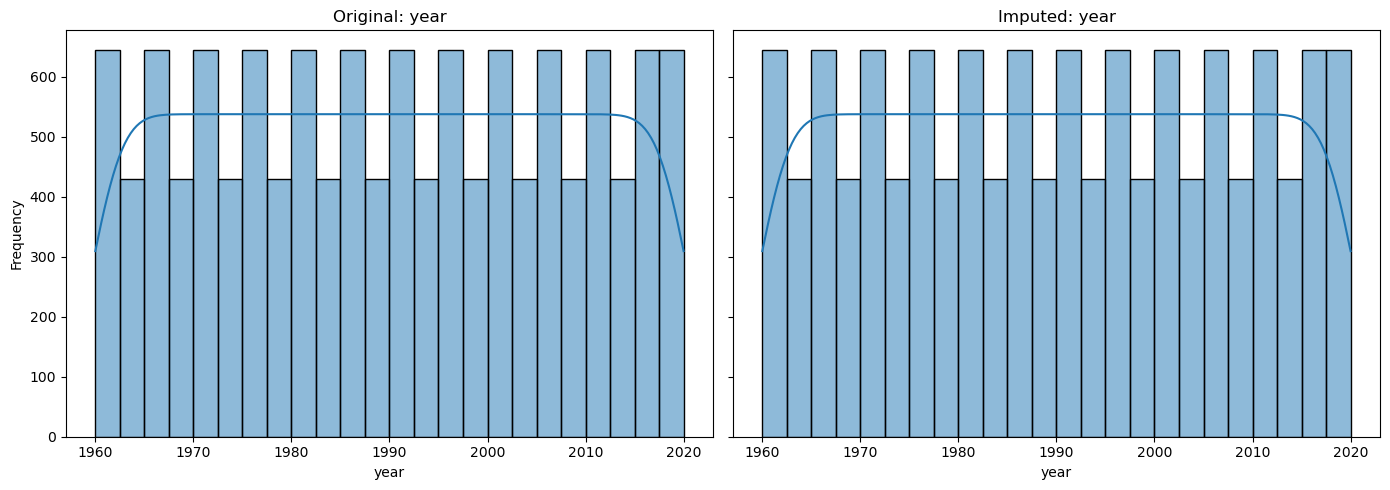


Column: Agricultural land (% of land area)
Original | Null%: 19.70, Skew: 0.16, Kurt: -1.00, Mean: 37.03, Median: 37.67, Std: 22.43, Min: 0.26, Max: 93.44
Imputed | Null%: 0.00, Skew: 0.19, Kurt: -0.96, Mean: 36.70, Median: 37.04, Std: 21.97, Min: 0.26, Max: 93.44


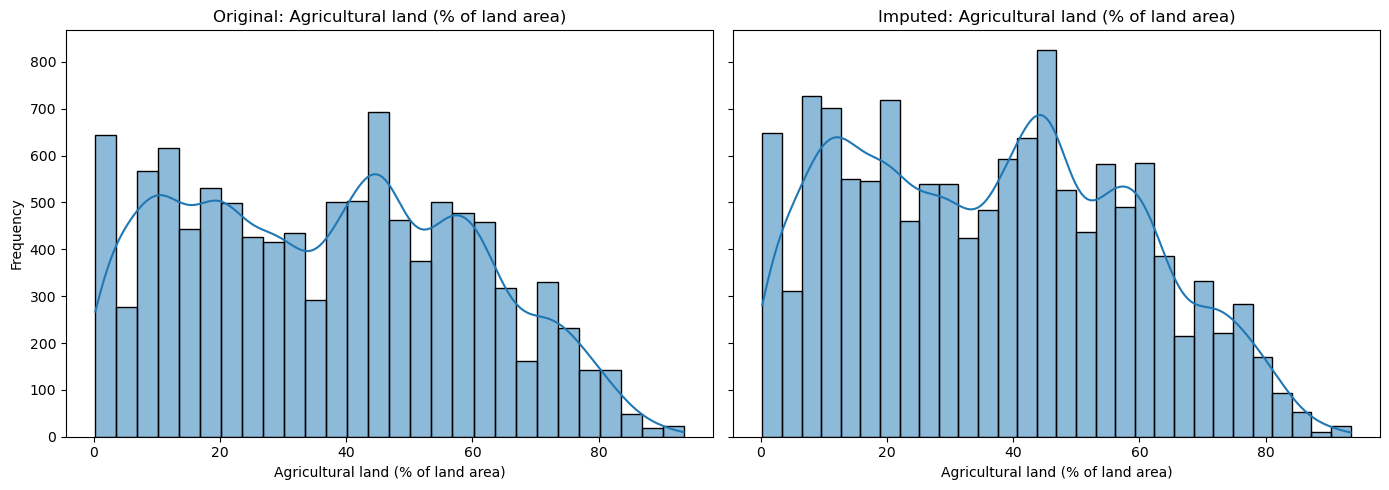


Column: Agricultural land (sq. km)
Original | Null%: 19.60, Skew: 5.36, Kurt: 31.92, Mean: 227747.69, Median: 28446.50, Std: 637768.12, Min: 3.00, Max: 5278330.00
Imputed | Null%: 0.00, Skew: 5.46, Kurt: 33.12, Mean: 215190.40, Median: 26500.00, Std: 619234.99, Min: 3.00, Max: 5278330.00


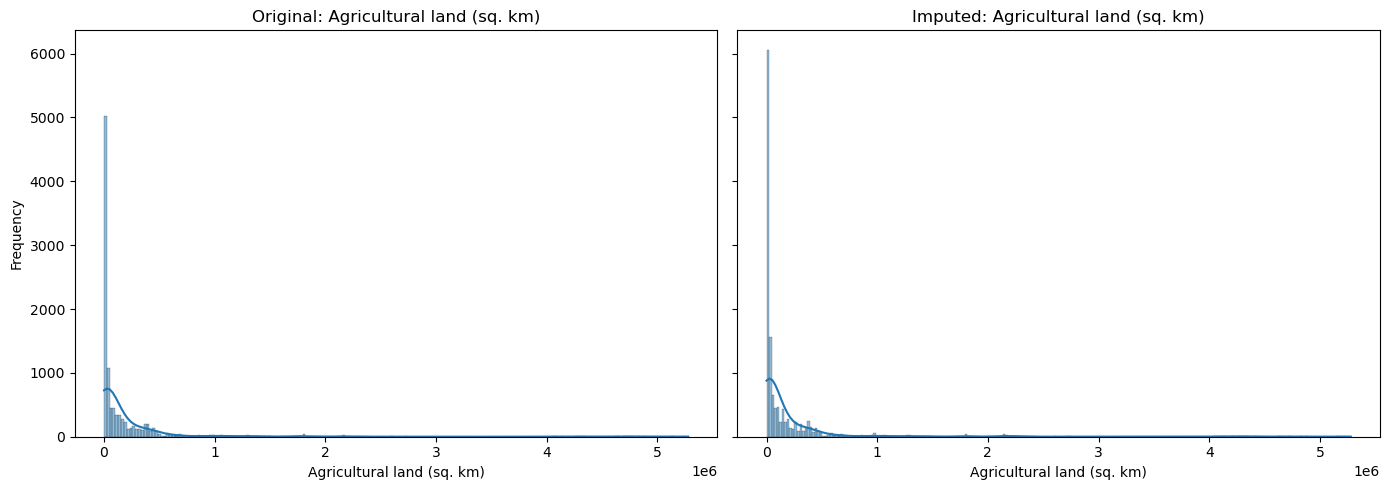


Column: Agricultural methane emissions (% of total)
Original | Null%: 39.90, Skew: -0.24, Kurt: -1.00, Mean: 47.77, Median: 50.22, Std: 26.61, Min: 0.00, Max: 99.23
Imputed | Null%: 0.00, Skew: -0.19, Kurt: -1.04, Mean: 45.72, Median: 48.14, Std: 26.54, Min: 0.00, Max: 99.23


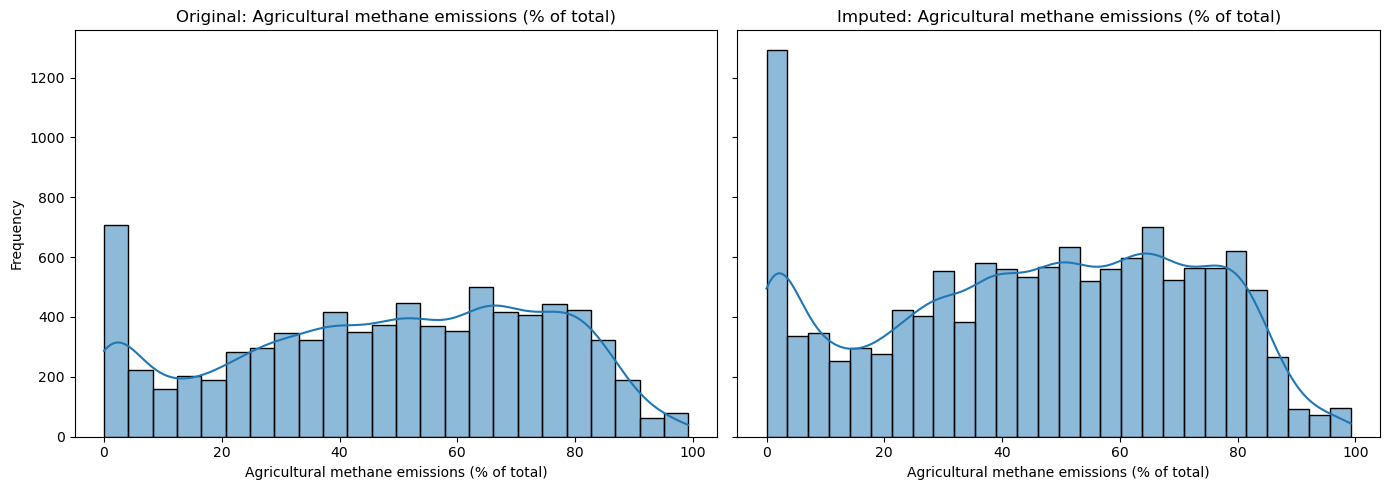


Column: Agricultural methane emissions (thousand metric tons of CO2 equivalent)
Original | Null%: 34.43, Skew: 7.71, Kurt: 69.40, Mean: 13874.47, Median: 1949.39, Std: 48176.41, Min: 0.00, Max: 581221.82
Imputed | Null%: 0.00, Skew: 8.02, Kurt: 80.06, Mean: 13066.16, Median: 1879.34, Std: 42531.09, Min: 0.00, Max: 581221.82


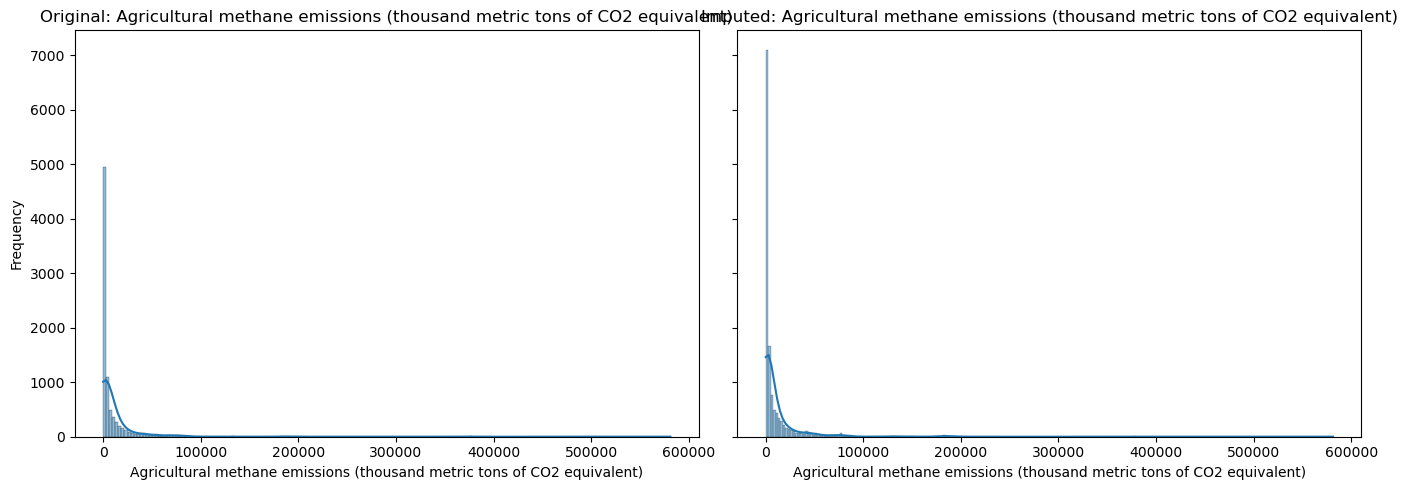


Column: Agricultural nitrous oxide emissions (% of total)
Original | Null%: 39.60, Skew: -0.93, Kurt: 0.06, Mean: 63.40, Median: 70.64, Std: 25.75, Min: 0.00, Max: 99.58
Imputed | Null%: 0.00, Skew: -0.87, Kurt: -0.13, Mean: 61.66, Median: 68.61, Std: 26.42, Min: 0.00, Max: 99.58


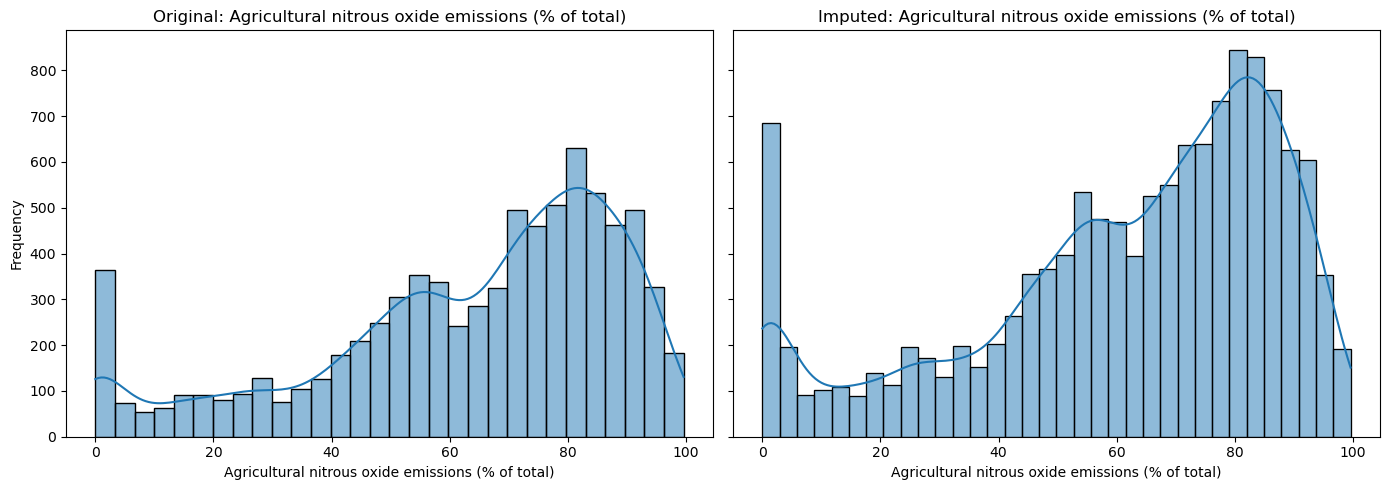


Column: Agricultural nitrous oxide emissions (thousand metric tons of CO2 equivalent)
Original | Null%: 34.43, Skew: 7.72, Kurt: 77.32, Mean: 7552.66, Median: 1341.79, Std: 23825.75, Min: 0.00, Max: 375435.62
Imputed | Null%: 0.00, Skew: 7.27, Kurt: 69.91, Mean: 7623.76, Median: 1256.74, Std: 23223.50, Min: 0.00, Max: 375435.62


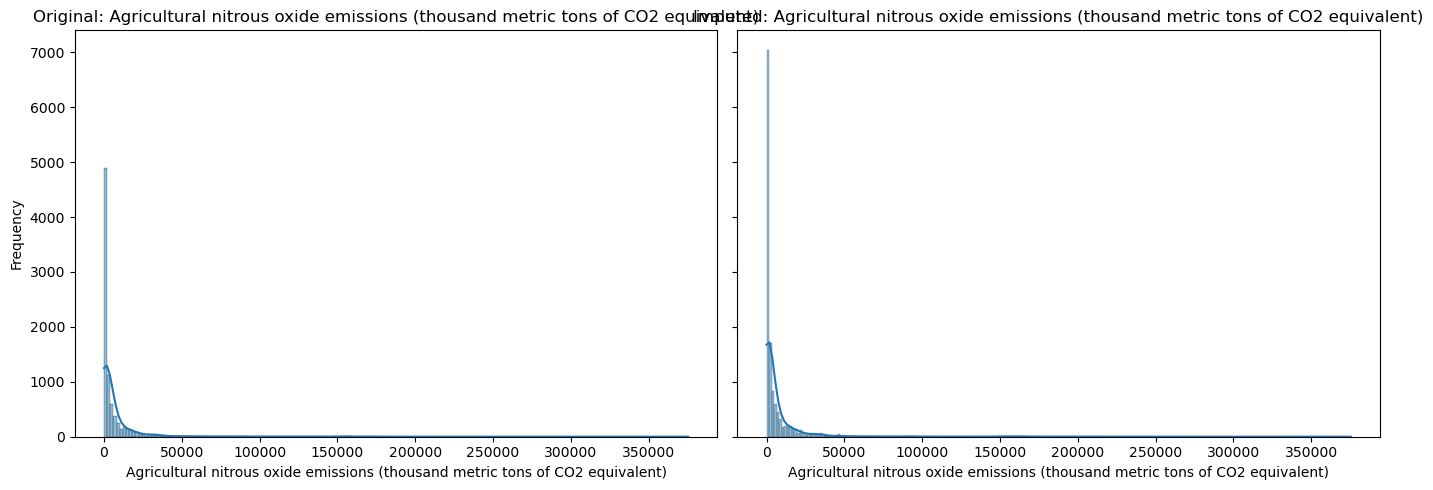


Column: Agricultural raw materials exports (% of merchandise exports)
Original | Null%: 45.98, Skew: 3.42, Kurt: 14.02, Mean: 6.50, Median: 2.25, Std: 11.56, Min: 0.00, Max: 98.95
Imputed | Null%: 0.00, Skew: 2.98, Kurt: 10.73, Mean: 7.10, Median: 2.67, Std: 11.48, Min: 0.00, Max: 98.95


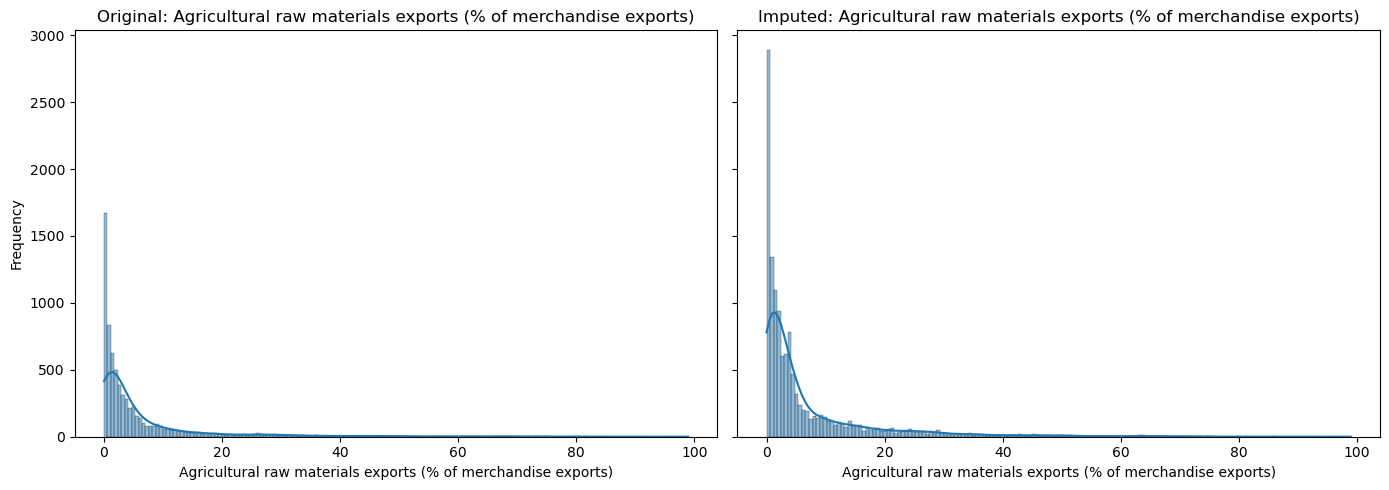


Column: Agricultural raw materials imports (% of merchandise imports)
Original | Null%: 45.48, Skew: 4.67, Kurt: 44.90, Mean: 2.29, Median: 1.63, Std: 2.44, Min: 0.00, Max: 47.75
Imputed | Null%: 0.00, Skew: 4.56, Kurt: 42.39, Mean: 2.20, Median: 1.67, Std: 2.22, Min: 0.00, Max: 47.75


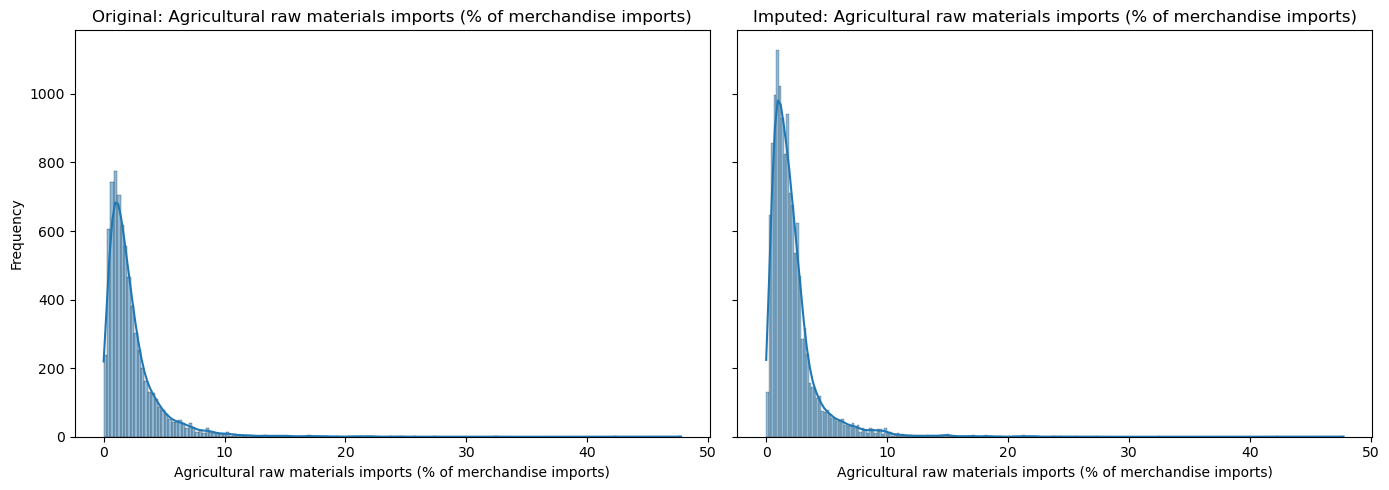


Column: Agriculture, forestry, and fishing, value added (% of GDP)
Original | Null%: 40.82, Skew: 1.12, Kurt: 1.04, Mean: 16.64, Median: 12.38, Std: 14.64, Min: 0.03, Max: 89.41
Imputed | Null%: 0.00, Skew: 1.09, Kurt: 0.97, Mean: 15.87, Median: 11.88, Std: 14.09, Min: 0.03, Max: 89.41


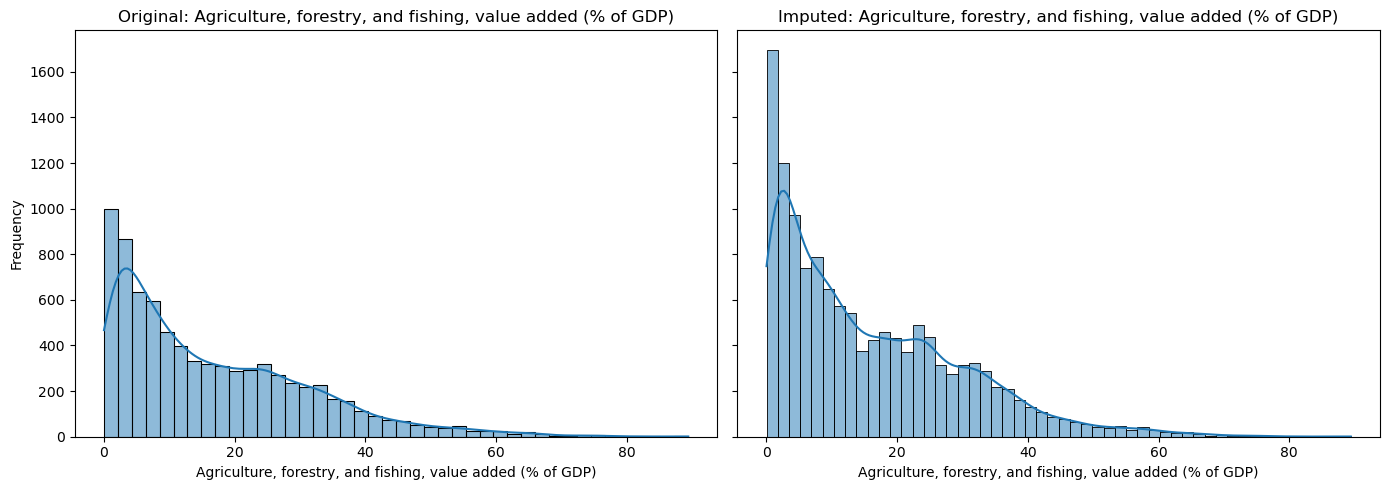


Column: Agriculture, forestry, and fishing, value added (current US$)
Original | Null%: 41.32, Skew: 16.60, Kurt: 348.71, Mean: 8169947498.61, Median: 1085766343.00, Std: 38848178548.10, Min: 2256903.64, Max: 1020000000000.00
Imputed | Null%: 0.00, Skew: 19.61, Kurt: 501.98, Mean: 6304246196.57, Median: 677489900.00, Std: 32116371795.64, Min: 2256903.64, Max: 1020000000000.00


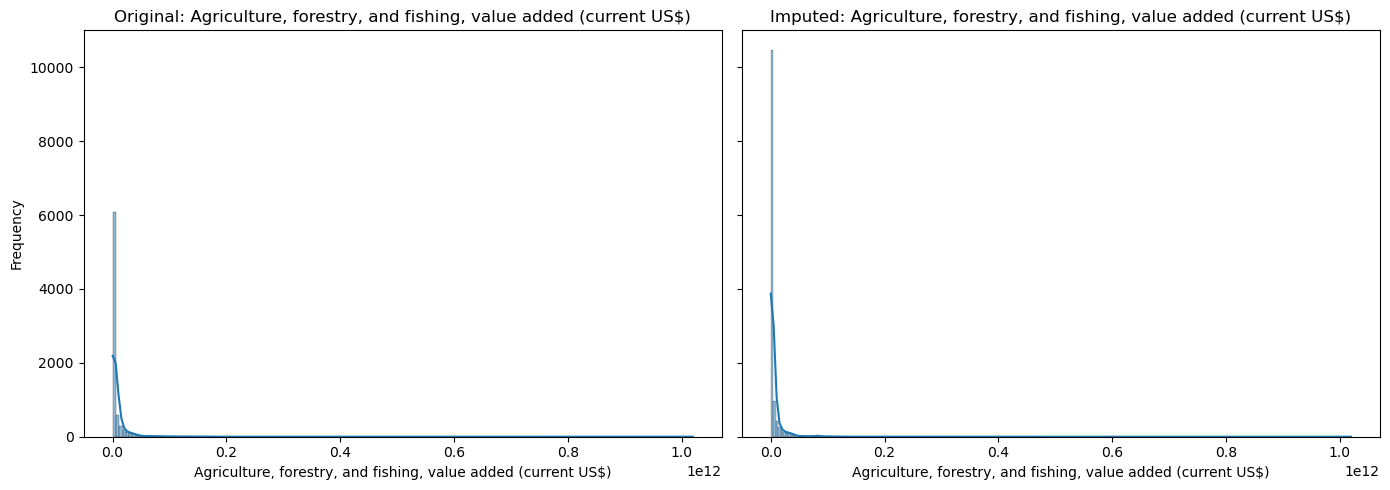


Column: Arable land (% of land area)
Original | Null%: 20.74, Skew: 1.46, Kurt: 1.94, Mean: 13.51, Median: 9.55, Std: 13.53, Min: 0.00, Max: 73.39
Imputed | Null%: 0.00, Skew: 1.48, Kurt: 2.14, Mean: 13.27, Median: 9.73, Std: 13.10, Min: 0.00, Max: 73.39


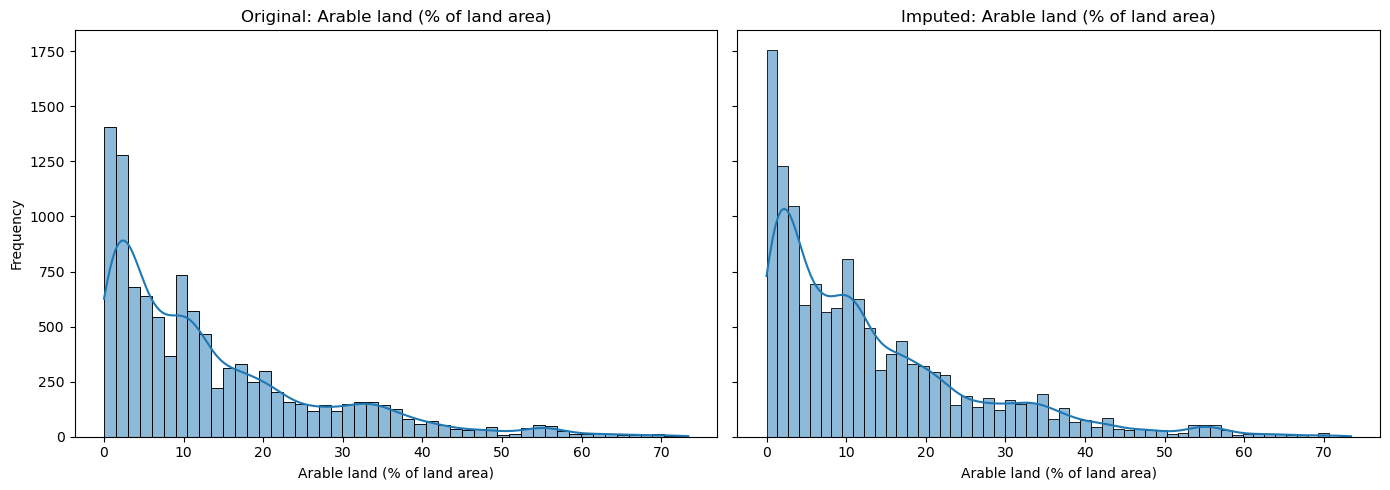


Column: Arable land (hectares per person)
Original | Null%: 20.80, Skew: 4.28, Kurt: 27.36, Mean: 0.26, Median: 0.18, Std: 0.33, Min: 0.00, Max: 3.50
Imputed | Null%: 0.00, Skew: 4.18, Kurt: 26.65, Mean: 0.25, Median: 0.18, Std: 0.32, Min: 0.00, Max: 3.50


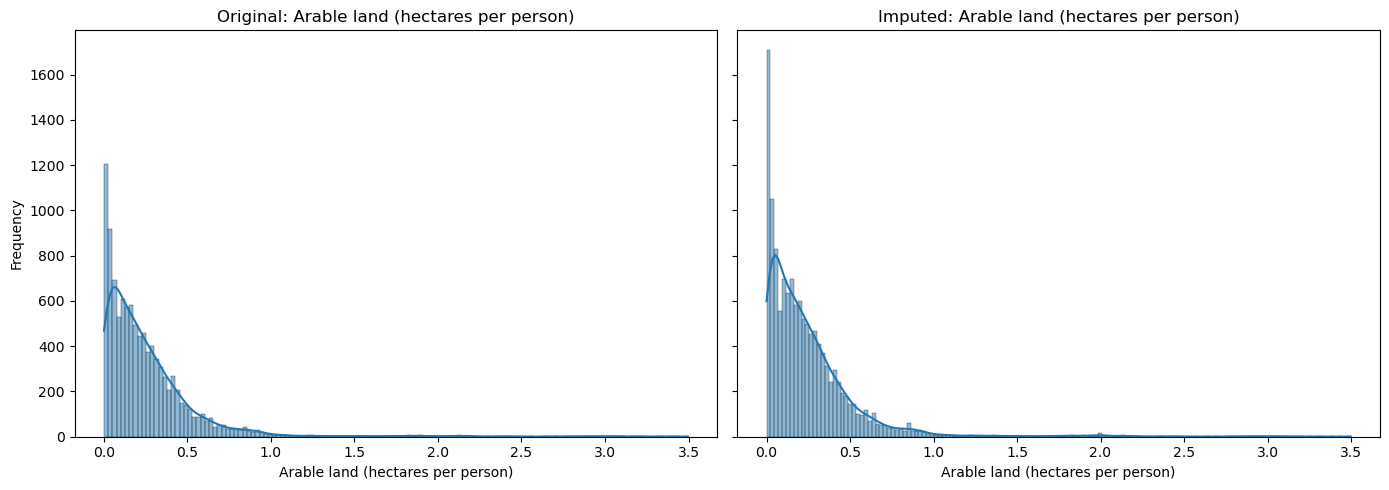


Column: Arable land (hectares)
Original | Null%: 20.69, Skew: 6.15, Kurt: 41.47, Mean: 6563167.27, Median: 1027000.00, Std: 21124514.42, Min: 140.00, Max: 189244000.00
Imputed | Null%: 0.00, Skew: 6.35, Kurt: 44.02, Mean: 6246996.54, Median: 911799.99, Std: 20837010.36, Min: 140.00, Max: 189244000.00


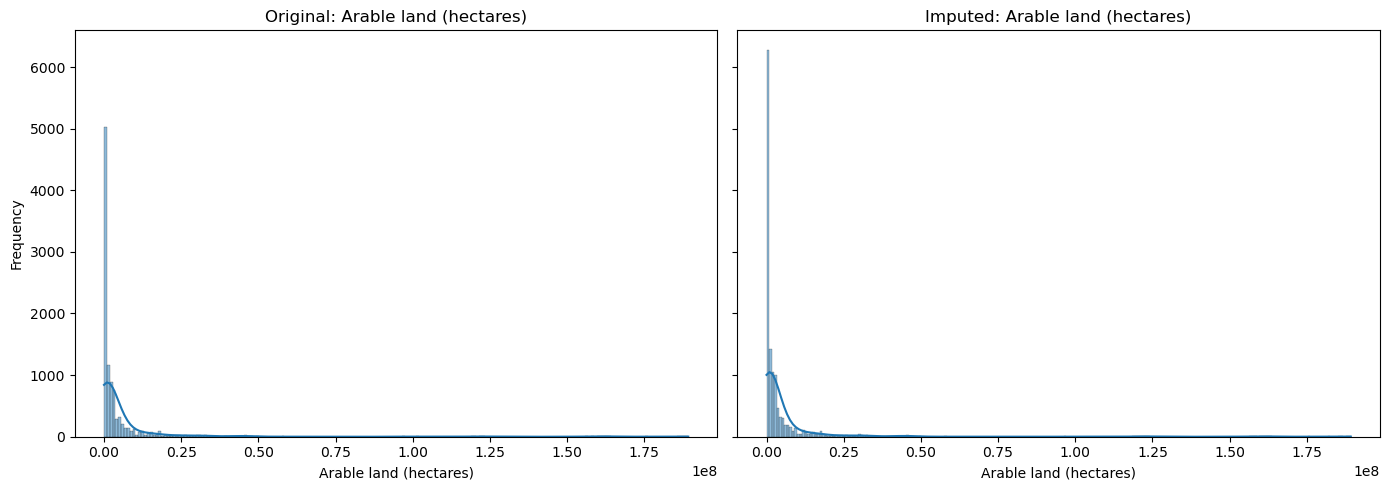


Column: Birth rate, crude (per 1,000 people)
Original | Null%: 10.69, Skew: 0.15, Kurt: -1.31, Mean: 28.54, Median: 27.47, Std: 13.13, Min: 5.90, Max: 58.23
Imputed | Null%: 0.00, Skew: 0.25, Kurt: -1.28, Mean: 27.66, Median: 25.53, Std: 13.06, Min: 5.90, Max: 58.23


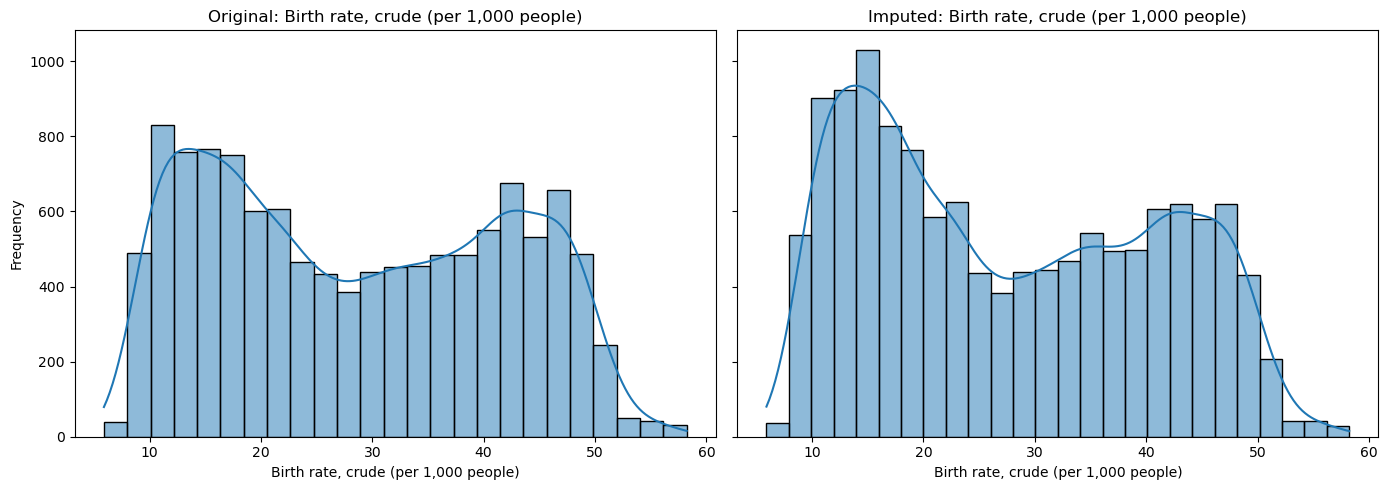


Column: Cereal production (metric tons)
Original | Null%: 30.48, Skew: 7.98, Kurt: 73.73, Mean: 10788095.87, Median: 1008800.00, Std: 42395582.00, Min: 0.00, Max: 621439200.00
Imputed | Null%: 0.00, Skew: 9.01, Kurt: 94.43, Mean: 8555450.36, Median: 542100.00, Std: 37835461.33, Min: 0.00, Max: 621439200.00


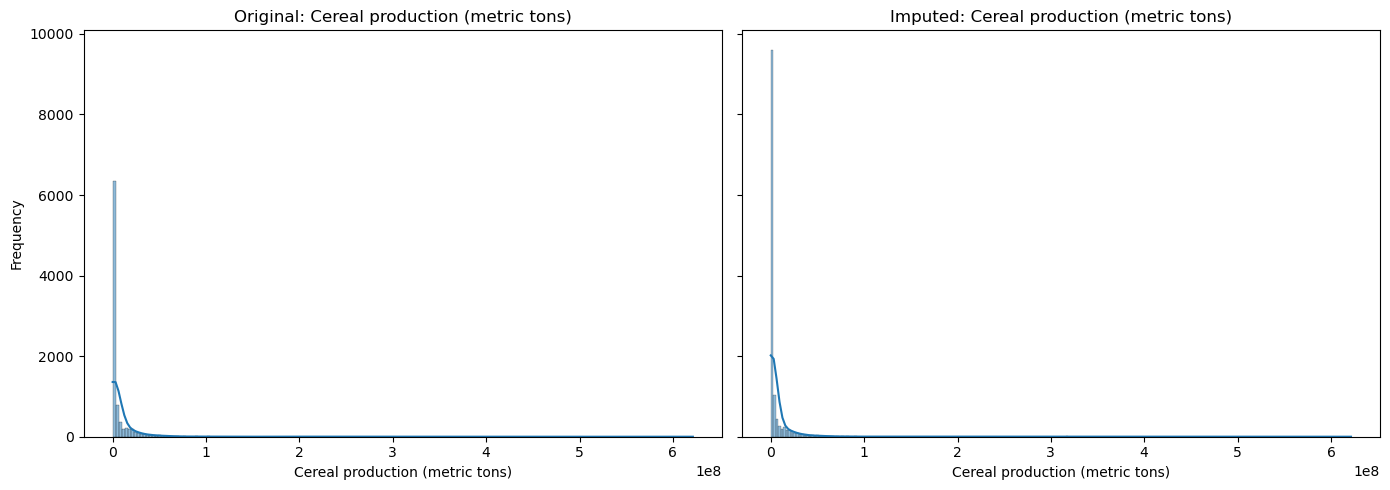


Column: Cereal yield (kg per hectare)
Original | Null%: 30.77, Skew: 3.88, Kurt: 30.79, Mean: 2392.20, Median: 1800.00, Std: 2036.85, Min: 34.30, Max: 28130.10
Imputed | Null%: 0.00, Skew: 4.04, Kurt: 34.18, Mean: 2300.96, Median: 1772.80, Std: 1863.89, Min: 34.30, Max: 28130.10


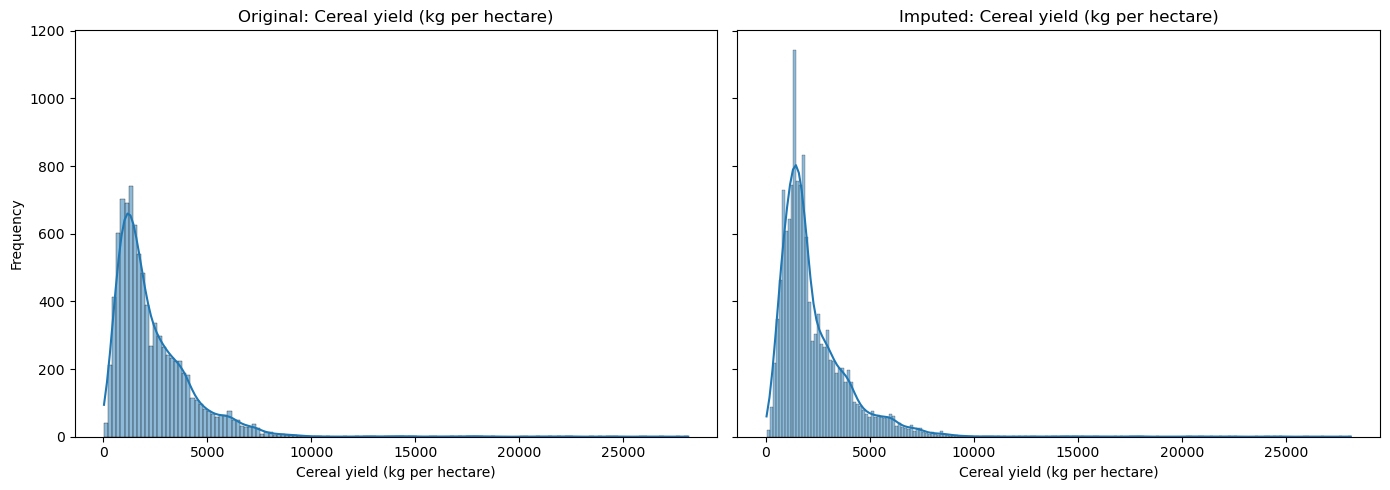


Column: Crop production index (2004-2006 = 100)
Original | Null%: 22.75, Skew: 2.88, Kurt: 18.34, Mean: 87.10, Median: 85.66, Std: 48.51, Min: 0.09, Max: 665.07
Imputed | Null%: 0.00, Skew: 2.73, Kurt: 15.55, Mean: 88.73, Median: 86.89, Std: 49.13, Min: 0.09, Max: 665.07


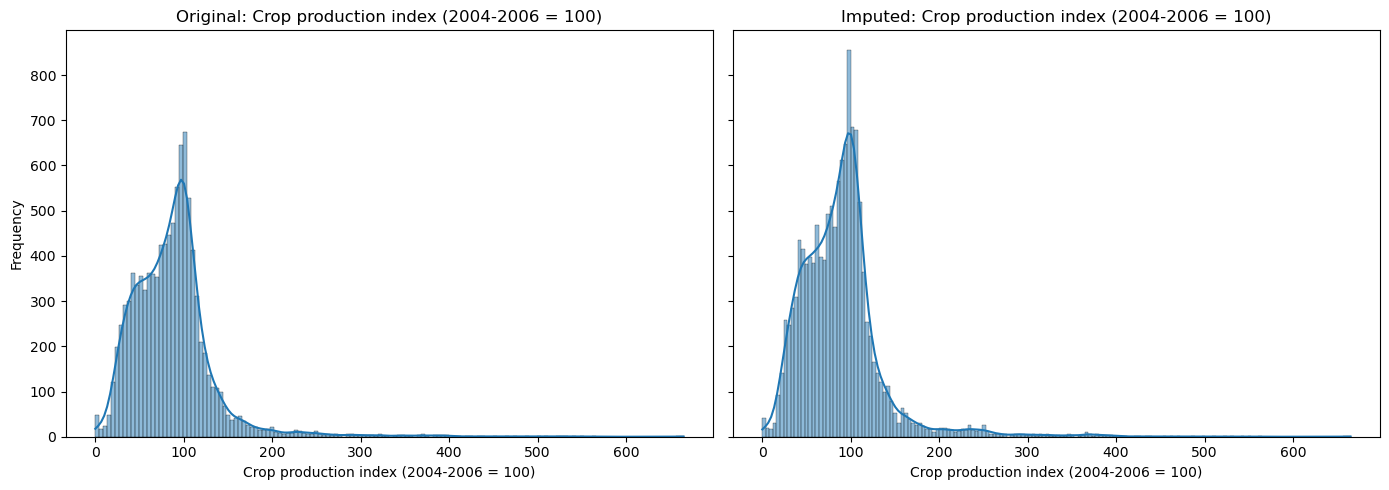


Column: Death rate, crude (per 1,000 people)
Original | Null%: 10.87, Skew: 1.55, Kurt: 3.47, Mean: 10.57, Median: 9.20, Std: 5.45, Min: 1.13, Max: 54.44
Imputed | Null%: 0.00, Skew: 1.57, Kurt: 3.58, Mean: 10.23, Median: 8.80, Std: 5.38, Min: 1.13, Max: 54.44


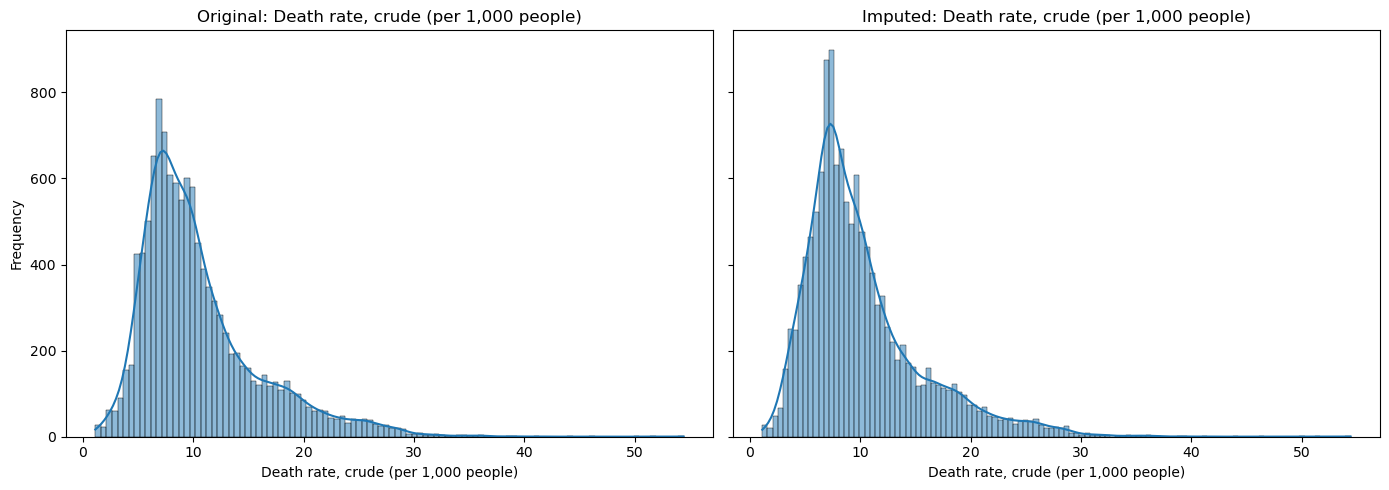


Column: Food production index (2004-2006 = 100)
Original | Null%: 21.88, Skew: 8.35, Kurt: 132.14, Mean: 84.72, Median: 85.88, Std: 52.72, Min: 0.07, Max: 1094.43
Imputed | Null%: 0.00, Skew: 7.56, Kurt: 120.72, Mean: 86.11, Median: 86.71, Std: 50.76, Min: 0.07, Max: 1094.43


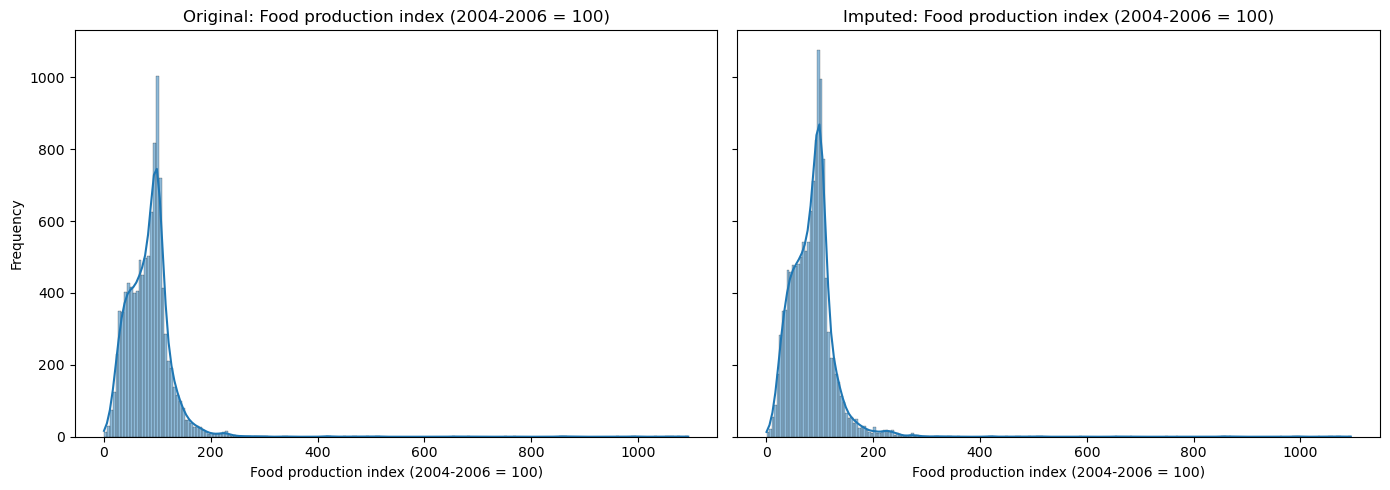


Column: GDP per capita (current US$)
Original | Null%: 25.48, Skew: 4.18, Kurt: 25.50, Mean: 8447.65, Median: 1909.74, Std: 16618.11, Min: 34.79, Max: 189422.22
Imputed | Null%: 0.00, Skew: 4.40, Kurt: 25.18, Mean: 9229.65, Median: 2079.67, Std: 19287.63, Min: 34.79, Max: 189422.22


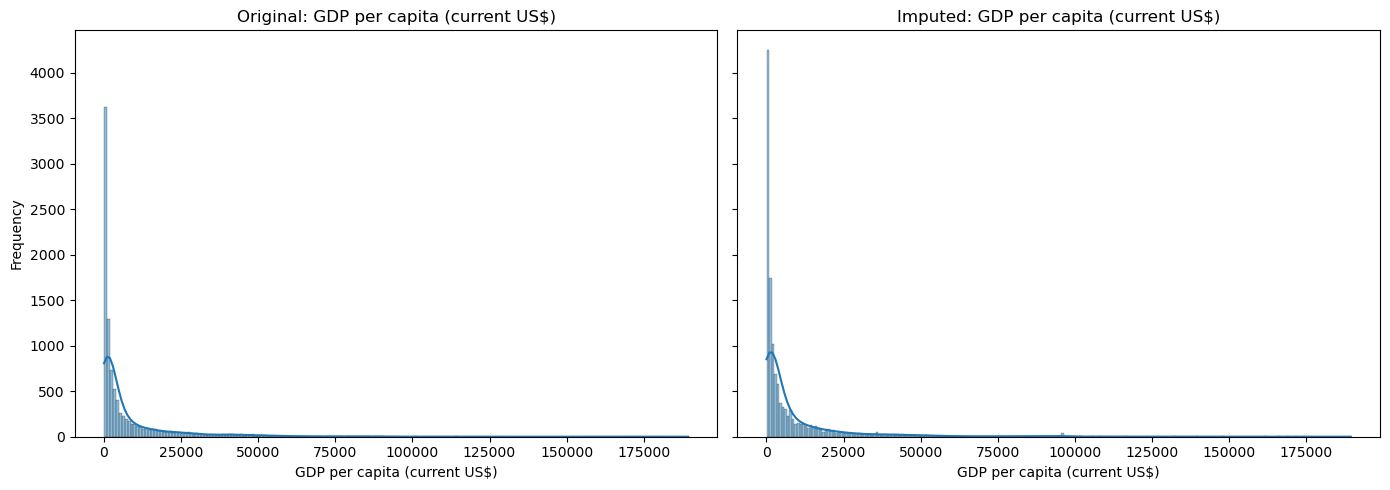


Column: Land area (sq. km)
Original | Null%: 7.35, Skew: 5.74, Kurt: 37.97, Mean: 607531.64, Median: 96320.00, Std: 1772516.43, Min: 2.00, Max: 16389950.00
Imputed | Null%: 0.00, Skew: 5.79, Kurt: 38.85, Mean: 601209.35, Median: 94280.00, Std: 1752633.92, Min: 2.00, Max: 16389950.00


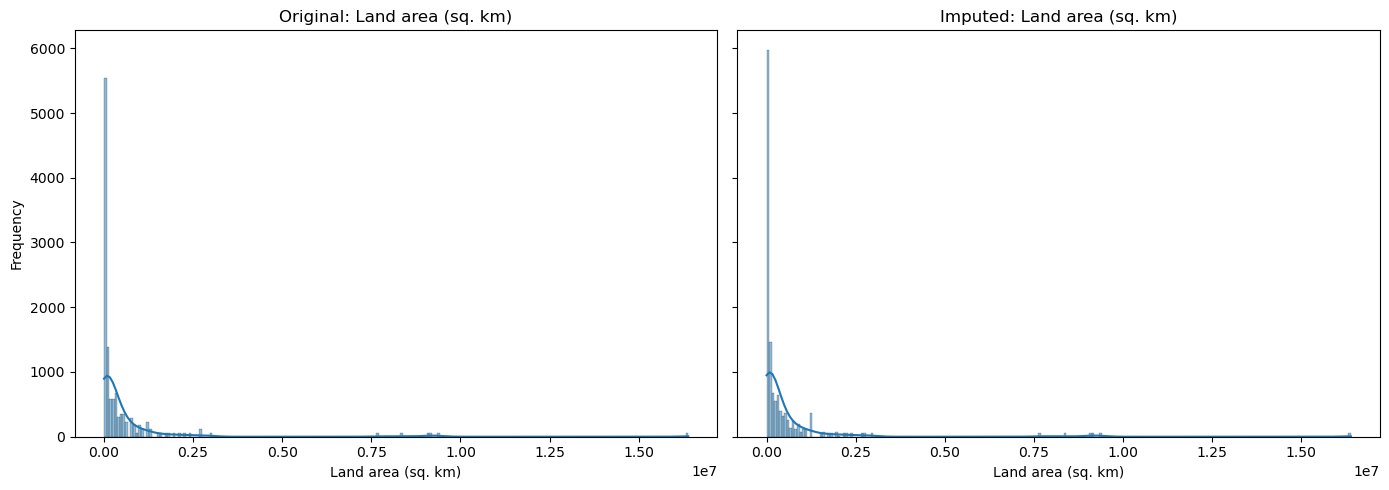


Column: Land under cereal production (hectares)
Original | Null%: 30.69, Skew: 6.21, Kurt: 41.65, Mean: 3883756.11, Median: 656975.00, Std: 12241560.86, Min: 0.00, Max: 106613208.00
Imputed | Null%: 0.00, Skew: 6.97, Kurt: 53.77, Mean: 3065886.90, Median: 332935.00, Std: 10724340.27, Min: 0.00, Max: 106613208.00


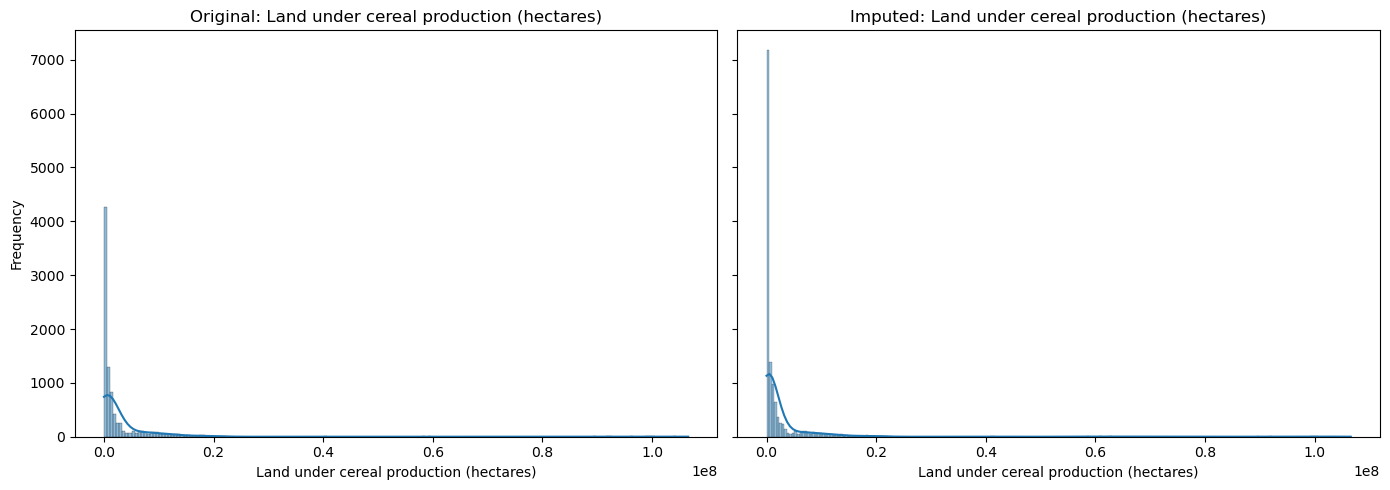


Column: Livestock production index (2004-2006 = 100)
Original | Null%: 22.15, Skew: 9.30, Kurt: 155.03, Mean: 81.71, Median: 83.20, Std: 56.83, Min: 4.32, Max: 1224.92
Imputed | Null%: 0.00, Skew: 8.47, Kurt: 144.47, Mean: 82.82, Median: 83.97, Std: 54.40, Min: 4.32, Max: 1224.92


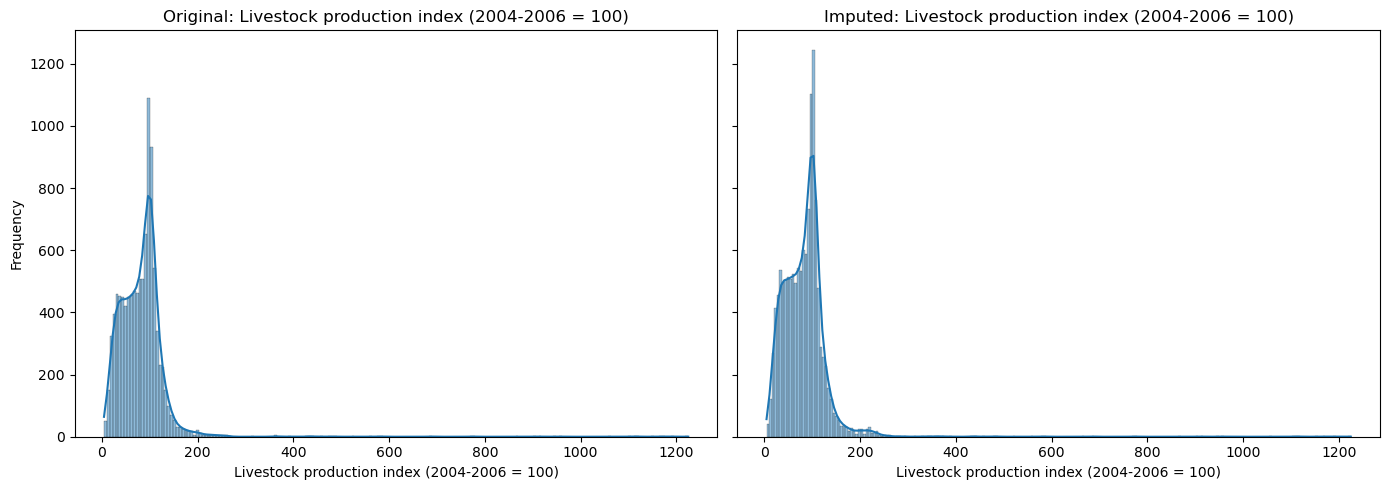


Column: Mineral rents (% of GDP)
Original | Null%: 35.04, Skew: 5.40, Kurt: 37.96, Mean: 1.01, Median: 0.00, Std: 3.27, Min: -0.00, Max: 46.91
Imputed | Null%: 0.00, Skew: 5.65, Kurt: 43.31, Mean: 0.93, Median: 0.00, Std: 2.90, Min: 0.00, Max: 46.91


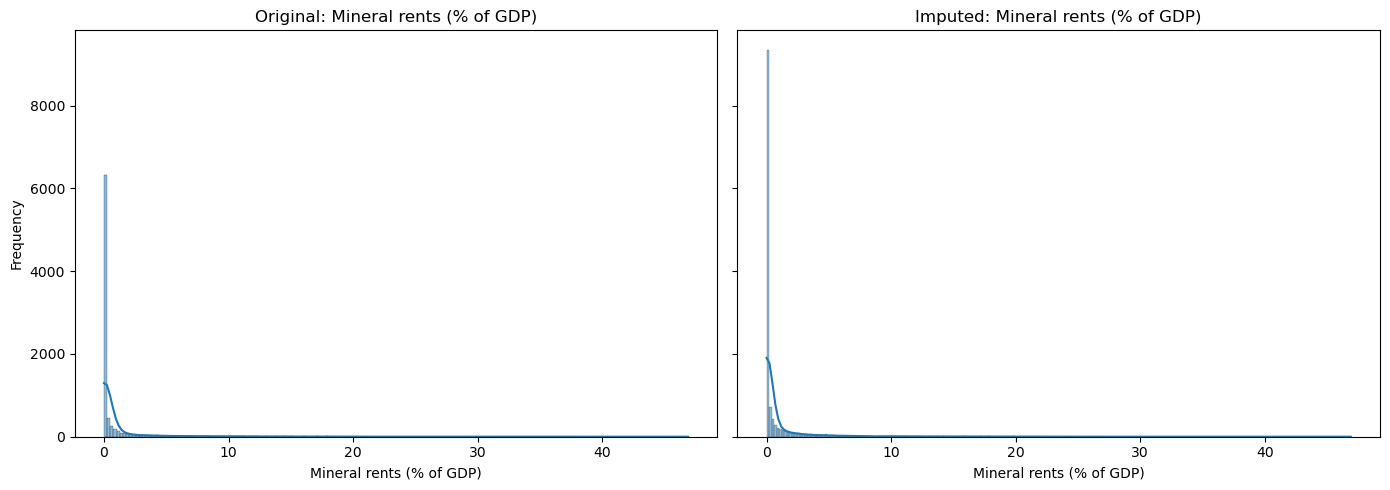


Column: Mortality rate, infant (per 1,000 live births)
Original | Null%: 21.08, Skew: 1.16, Kurt: 0.85, Mean: 51.20, Median: 36.75, Std: 45.57, Min: 1.50, Max: 279.70
Imputed | Null%: 0.00, Skew: 1.19, Kurt: 0.96, Mean: 50.21, Median: 36.60, Std: 44.53, Min: 1.50, Max: 279.70


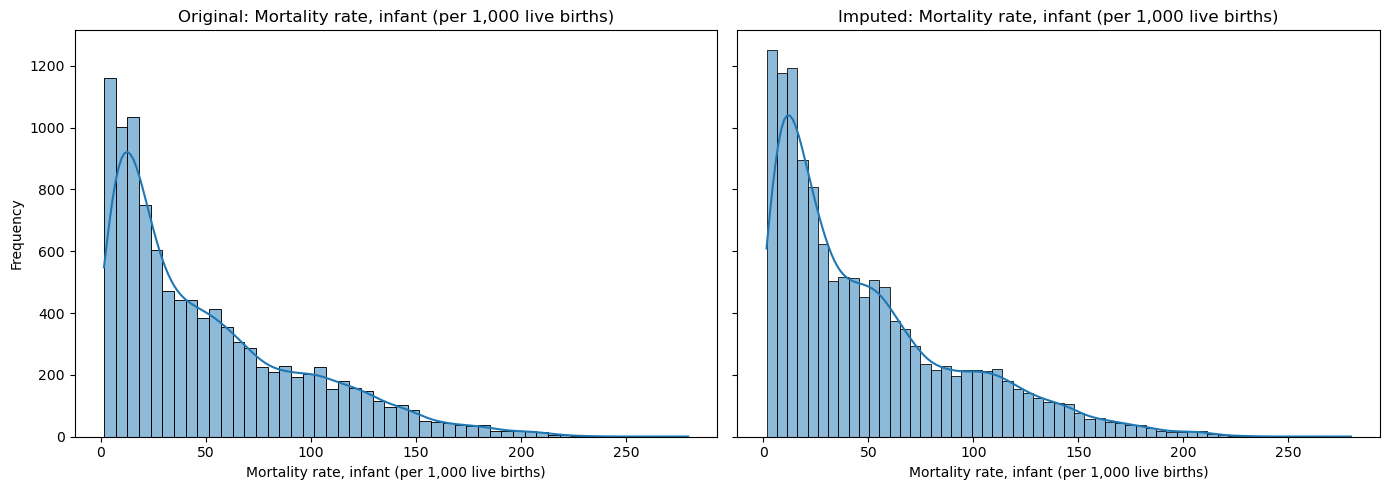


Column: Permanent cropland (% of land area)
Original | Null%: 25.43, Skew: 3.96, Kurt: 20.22, Mean: 4.54, Median: 1.38, Std: 8.31, Min: 0.00, Max: 66.67
Imputed | Null%: 0.00, Skew: 3.86, Kurt: 18.00, Mean: 5.04, Median: 1.74, Std: 9.23, Min: 0.00, Max: 66.67


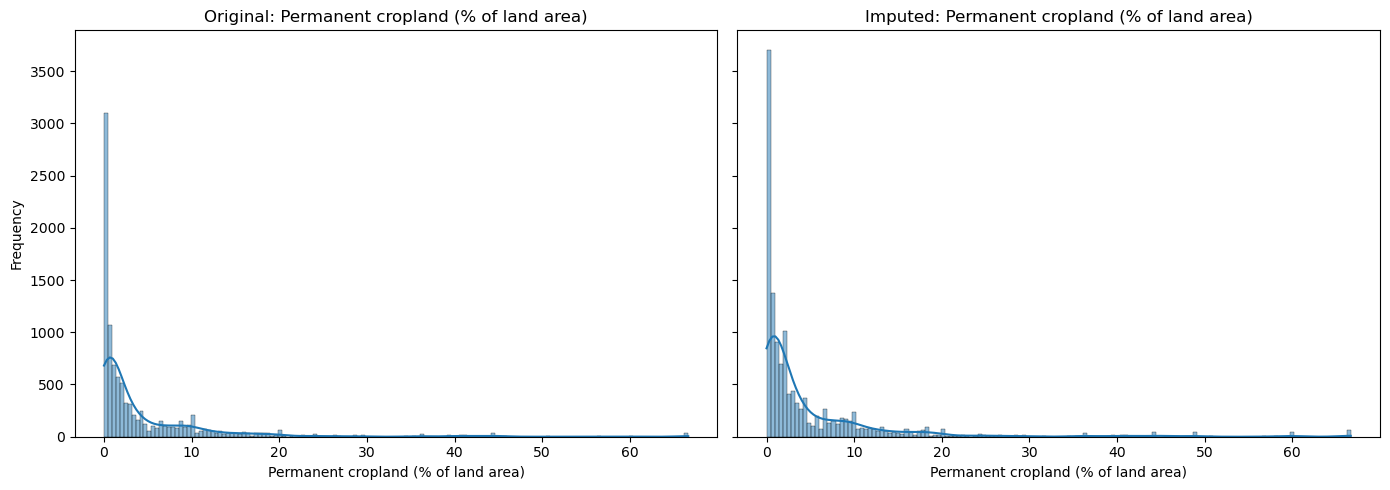


Column: Population, total
Original | Null%: 2.24, Skew: 9.71, Kurt: 105.14, Mean: 24474628.24, Median: 4135659.00, Std: 102485652.62, Min: 3893.00, Max: 1397715000.00
Imputed | Null%: 0.00, Skew: 9.74, Kurt: 105.72, Mean: 24528088.32, Median: 4144592.00, Std: 102881366.64, Min: 3893.00, Max: 1397715000.00


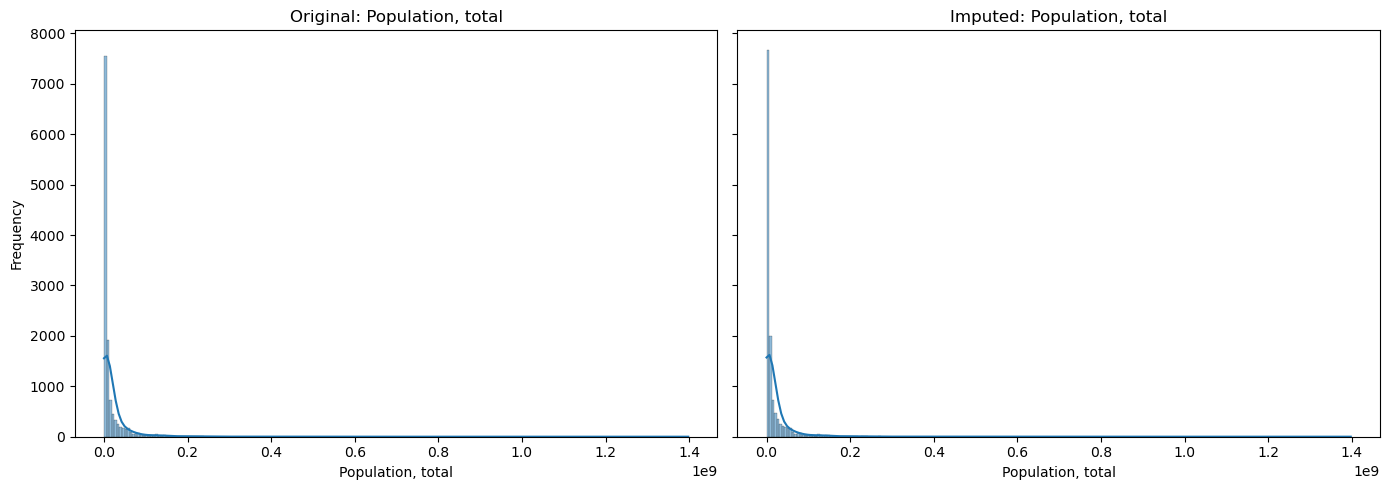


Column: Rural population
Original | Null%: 3.16, Skew: 10.02, Kurt: 105.67, Mean: 13554007.98, Median: 1828925.00, Std: 68617982.90, Min: 0.00, Max: 895386226.00
Imputed | Null%: 0.00, Skew: 10.09, Kurt: 107.42, Mean: 13394587.95, Median: 1754710.00, Std: 68193043.23, Min: 0.00, Max: 895386226.00


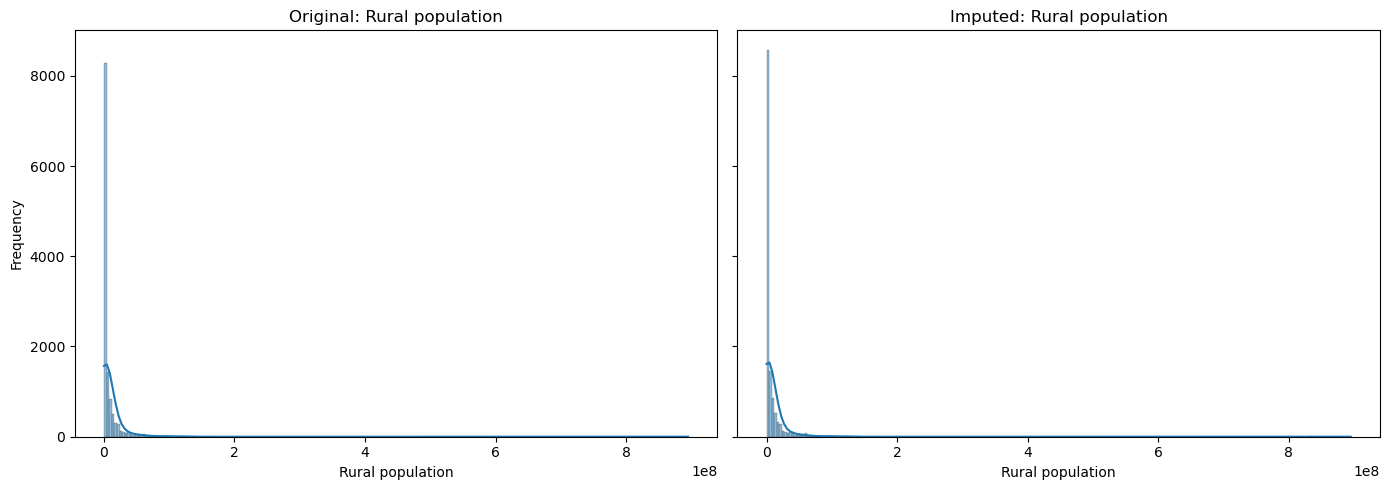


Column: Rural population (% of total population)
Original | Null%: 2.84, Skew: -0.16, Kurt: -0.98, Mean: 49.09, Median: 50.03, Std: 25.70, Min: 0.00, Max: 97.92
Imputed | Null%: 0.00, Skew: -0.16, Kurt: -0.99, Mean: 48.48, Median: 49.53, Std: 25.98, Min: 0.00, Max: 97.92


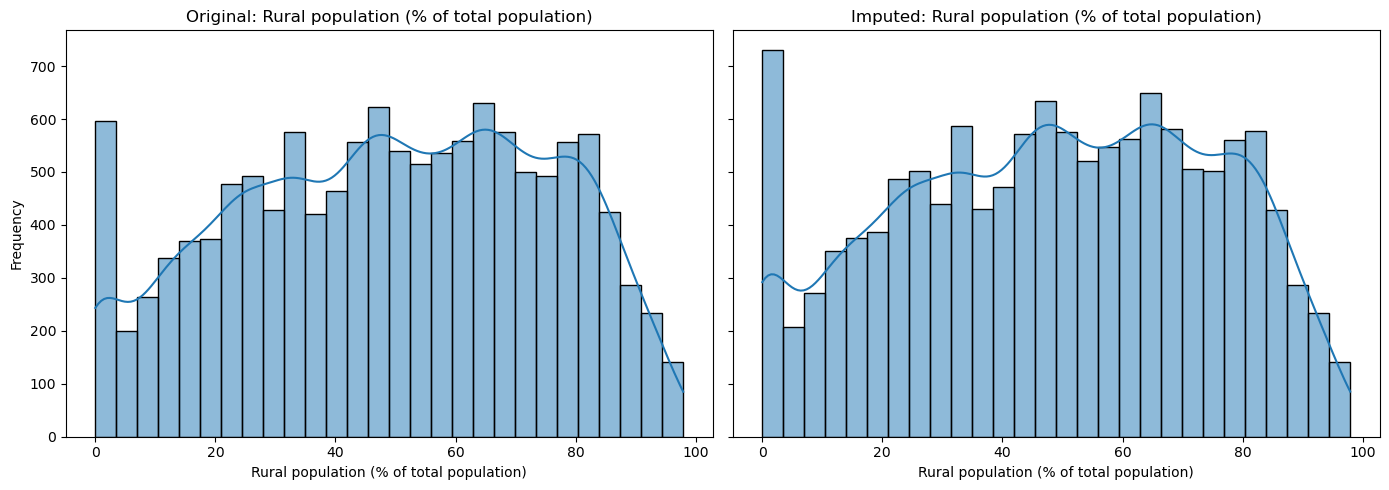


Column: Rural population growth (annual %)
Original | Null%: 8.16, Skew: -33.19, Kurt: 1649.19, Mean: 0.59, Median: 0.80, Std: 4.11, Min: -235.79, Max: 29.63
Imputed | Null%: 0.00, Skew: -13.53, Kurt: 198.06, Mean: -0.24, Median: 0.67, Std: 11.84, Min: -235.79, Max: 29.63


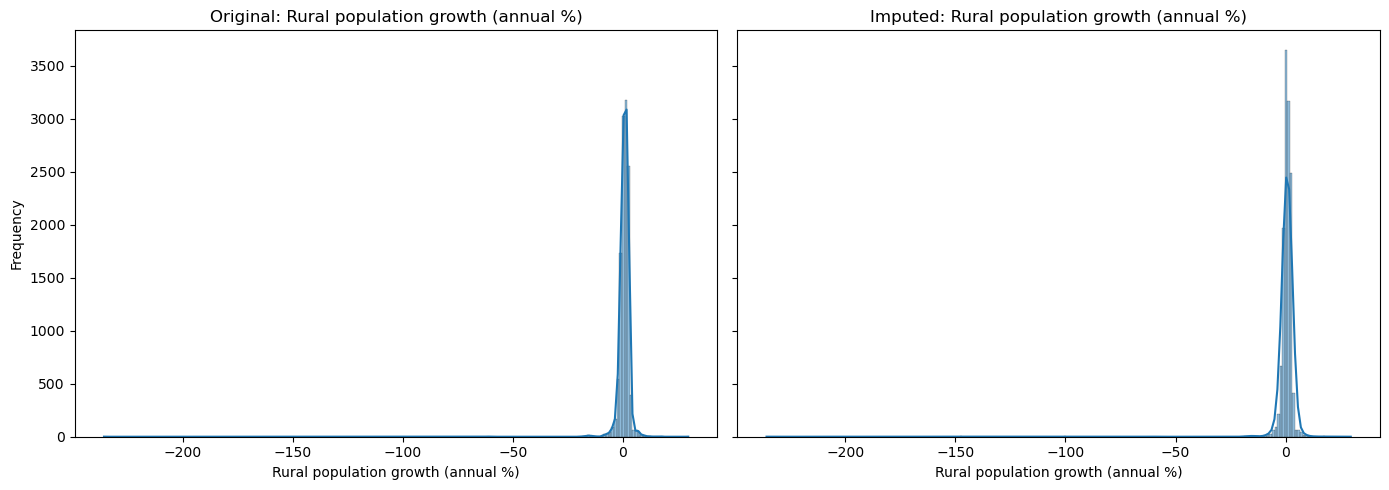


Column: Surface area (sq. km)
Original | Null%: 7.35, Skew: 5.77, Kurt: 38.36, Mean: 627971.56, Median: 103000.00, Std: 1847490.00, Min: 2.00, Max: 17098250.00
Imputed | Null%: 0.00, Skew: 5.83, Kurt: 39.25, Mean: 621313.64, Median: 99260.00, Std: 1826646.99, Min: 2.00, Max: 17098250.00


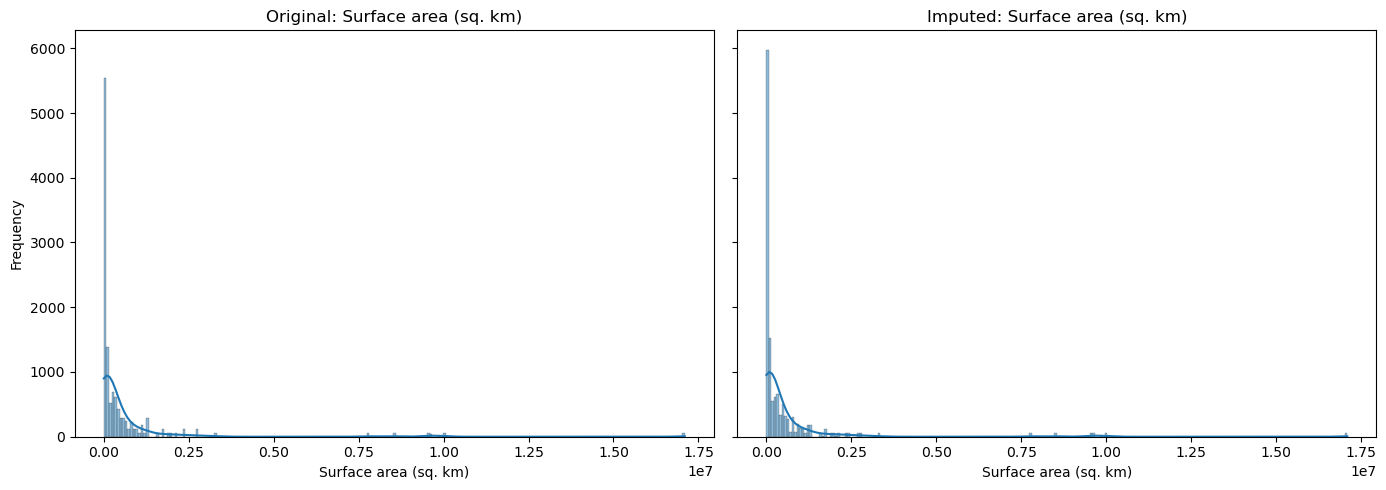

In [20]:
def plot_two_continuous_distributions(
    df1: pd.DataFrame,
    df2: pd.DataFrame,
) -> None:

    numeric_cols = df2.select_dtypes(include="number").columns

    for col in numeric_cols:

        print(f"\nColumn: {col}")

        for df, name in zip([df1, df2], ["Original", "Imputed"]):
            print(
                f"{name} | "
                f"Null%: {df[col].isna().mean()*100:.2f}, "
                f"Skew: {df[col].skew():.2f}, "
                f"Kurt: {df[col].kurtosis():.2f}, "
                f"Mean: {df[col].mean():.2f}, "
                f"Median: {df[col].median():.2f}, "
                f"Std: {df[col].std():.2f}, "
                f"Min: {df[col].min():.2f}, "
                f"Max: {df[col].max():.2f}"
            )

        # Create side-by-side plots
        fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

        sns.histplot(df1[col].dropna(), kde=True, ax=axes[0])
        axes[0].set_title(f"Original: {col}")
        axes[0].set_xlabel(col)
        axes[0].set_ylabel("Frequency")

        sns.histplot(df2[col].dropna(), kde=True, ax=axes[1])
        axes[1].set_title(f"Imputed: {col}")
        axes[1].set_xlabel(col)

        plt.tight_layout()
        plt.show()


# Compare the distribution of numeric columns before and after imputation
# to ensure that the imputation process has not introduced significant bias or change the distribution significantly.
plot_two_continuous_distributions(df_clean, df_impute)

# 4. Visualize the data (twice). Every submitted notebook should contain at least two visualizations using at least two different Python visualization libraries.
A list of the most wide-spread Python visualization libraries can be found in this article.

You must concisely describe and explain each visualization and your decisions in a Markdown field.

You will not receive the points for this task if you did not add a description/explanation. (max. 1.25 points per visualization)

Only the first two visualizations will be graded. Submitting more than two visualizations will not result in additional points.


## 4.1 1st Visualization - Global Urbanization Trend: Decline of Rural Population Over 60 Years
`Description:`
This heatmap visualizes the **Rural population (% of total population)** for a curated set of 20 countries spanning different continents and development levels, sampled at 5-year intervals from 1960 to 2020. 

`Design choices:`
- Objective is a presentation visualization.
- Seaborn heatmap was chosen for its ability to encode continuous values as color intensity, making temporal and cross-country comparison easier.
- A diverging color palette emphasizes the gradient from low rural percentage to high rural percentage.
- Countries are ordered by their 2020 rural population %, placing the most urbanized at the top and the most rural at the bottom, facilitating quick pattern recognition.
- Annotation with numeric values improves readability for precise comparisons.

`Insights:`
- There is a clear urbanization trend across countries around the worlds.
- Rapid urbanization in the fast developing countries: Countries like China, South Korea and Brazil were seen a remarkably decrease in % of rural area within just a few decades.
- Persistent rurality in parts of Africa and Asia (developing countries): Countries like Vietnam, Ethiopia and India still have large rural populations, though the trend is clearly downward.
- Already urbanized nations (developed countries): The US, Belgium, and Germany were already highly urbanized by 1960, showing minimal further change.
- De-urbanization: Austria is a special country as the urbanization trend was completely opposite.

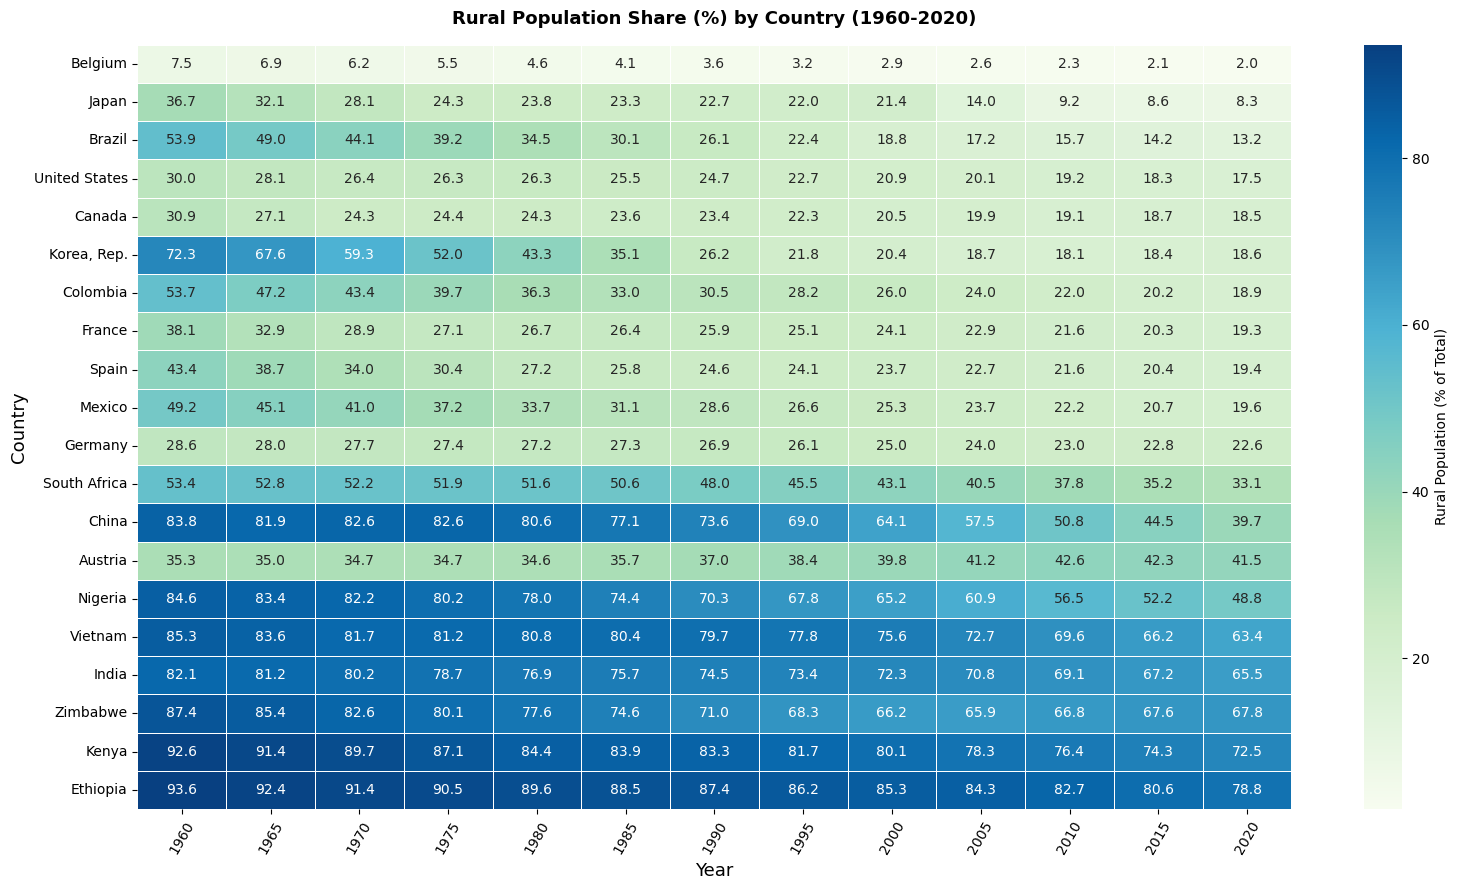

In [21]:
# Countries from different continents and development levels
selected_countries = [
    "Vietnam", "China", "India", "Korea, Rep.", "Japan",  # Asia
    "Austria", "Spain", "Belgium", "Germany", "France",  # Europe
    "Colombia", "Brazil", "Mexico", "United States", "Canada",  # Americas
    "Nigeria", "Ethiopia", "South Africa", "Kenya", "Zimbabwe",  # Africa
]

# Select 5-year intervals for a clean heatmap
selected_years = list(range(1960, 2025, 5))

# Filter and pivot
df_viz_1 = df_impute[
    (df_impute["Country Name"].isin(selected_countries)) &
    (df_impute["year"].isin(selected_years))
][["Country Name", "year", "Rural population (% of total population)"]].copy()

df_pivot = df_viz_1.pivot(
    index="Country Name",
    columns="year",
    values="Rural population (% of total population)"
)

# Order countries by their 2020 rural population % (most urban at top)
latest_year = max(selected_years)
df_pivot = df_pivot.sort_values(by=latest_year, ascending=True)

# Plot
fig, ax = plt.subplots(figsize=(16, 9))
sns.heatmap(
    df_pivot,
    annot=True,
    fmt=".1f",
    cmap="GnBu",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Rural Population (% of Total)"},
    ax=ax,
)
ax.set_title(
    f"Rural Population Share (%) by Country (1960-{latest_year})",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Year", fontsize=13)
ax.set_ylabel("Country", fontsize=13)
ax.set_xticklabels([int(y) for y in df_pivot.columns], rotation=60)

plt.tight_layout()
plt.show()

## 4.2 2nd Visualization - Structural Transformation: GDP per Capita vs Agriculture's Share of GDP

`Description:`
This scatter plot shows the relationship between **GDP per capita (current US$)** and **Agriculture, forestry, and fishing, value added (% of GDP)** for all countries in the year 2019 (pre-COVID). Each dot represents one country. The purpose is to answer our question that: "Are richer countries has lower Agriculture, forestry, and fishing, value added (negative correlation) ?"

`Design choices:`
- Objective is a confirmation visualization.
- Matplotlib scatter plot was chosen to compare two variables across many countries at a single point in time (a year).
- A logarithmic x-axis (GDP per capita) is used because GDP per capita is highly right-skewed; the log scale spreads out the data and reveals the relationship more clearly.
- Some countries are annotated to provide narrative context directly on the chart.
- A polynomial trend line is overlaid to make the overall pattern clearer.

`Insights:`
- As countries grow wealthier (higher GDP per capita), the share of agriculture in their economy shrinks dramatically.
- The relationship follows a clear exponential decay pattern: poorer countries often have 30-60% of GDP in agriculture, while rich countries have under 5%.
- This pattern reflects the transition from agricultural to industrial and service-based economies, which is a fundamental feature of modern economic development.
- The trend line fits the data reasonably well, and the story matches what we saw in the first chart, the countries that urbanized the fastest over past years are also the ones where agriculture plays the
smallest role today.
- There exists countries (outliers) which have a low GPD per capita but the percentage of agriculture, forestry, and fishing in their economy is also low.

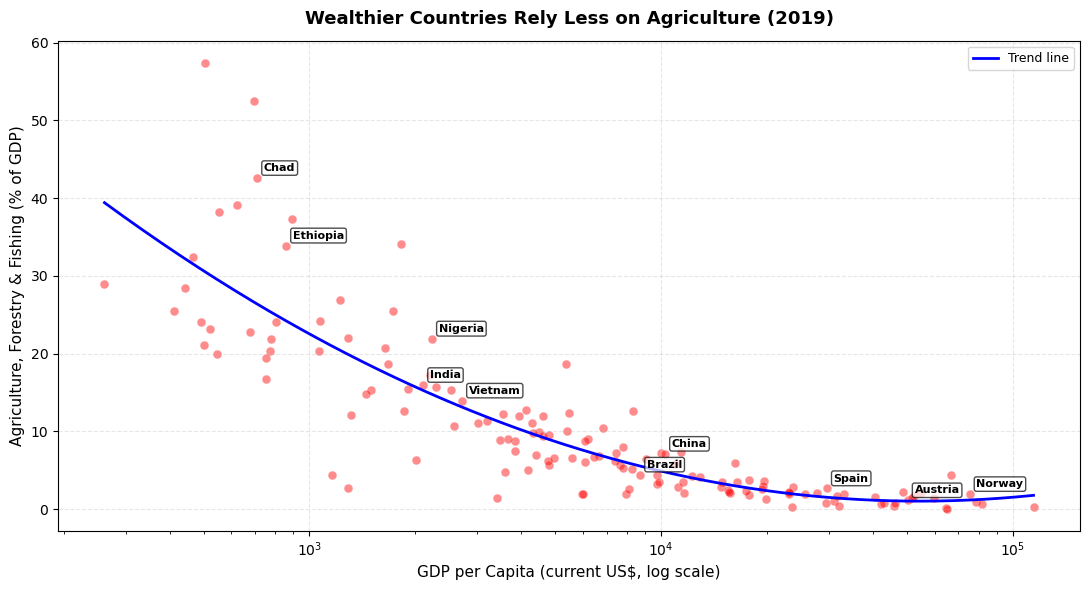

In [22]:
df_viz2 = df_clean[df_clean["year"] == 2019][[
    "Country Name",
    "GDP per capita (current US$)",
    "Agriculture, forestry, and fishing, value added (% of GDP)",
]].dropna().copy()

df_viz2 = df_viz2[
    (df_viz2["GDP per capita (current US$)"] > 0) &
    (df_viz2["Agriculture, forestry, and fishing, value added (% of GDP)"] > 0)
]

gdp = df_viz2["GDP per capita (current US$)"]
agri = df_viz2["Agriculture, forestry, and fishing, value added (% of GDP)"]

# Fit a polynomial trend line on log-scaled GDP
log_gdp = np.log10(gdp)
coeffs = np.polyfit(log_gdp, agri, deg=2)
x_range = np.linspace(log_gdp.min(), log_gdp.max(), 300)
y_trend = np.polyval(coeffs, x_range)

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(gdp, agri, alpha=0.45, color="red", edgecolors="white", linewidth=0.4, s=40)
ax.plot(10 ** x_range, y_trend, color="blue", linewidth=2, label="Trend line")

annotate = [
    "Austria", "Spain", "Chad", "Ethiopia", "Nigeria", "India",
    "Vietnam", "China", "Brazil", "Norway", "United States",
]
for _, row in df_viz2.iterrows():
    if row["Country Name"] in annotate:
        ax.annotate(
            row["Country Name"],
            (row["GDP per capita (current US$)"],
             row["Agriculture, forestry, and fishing, value added (% of GDP)"]),
            fontsize=8, fontweight="bold",
            xytext=(5, 5), textcoords="offset points",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7),
        )

ax.set_xscale("log")
ax.set_xlabel("GDP per Capita (current US$, log scale)", fontsize=11)
ax.set_ylabel("Agriculture, Forestry & Fishing (% of GDP)", fontsize=11)
ax.set_title("Wealthier Countries Rely Less on Agriculture (2019)", fontsize=13, fontweight="bold", pad=12)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

# 5. Save the resulting table as CSV.
To be sure that the data is correctly saved, you can load it again. You will have to work with this clean dataset for the second exercise. (0.5 points)

In [23]:
save_file_name = "agriRuralDevelopment_cleaned.csv"

df_impute.to_csv(
    save_file_name,
    index=False,
)

df_impute = pd.read_csv(save_file_name)

print(df_impute.shape)

(13115, 34)
